### Fill in group number and member names:

In [ ]:
GROUP = "27"
NAME1 = "Gustaf Utterström"
NAME2 = "Philip Rosengren"

# Optimization for learning - FRTN50

## Assignment 2

The purpose of this assignment is to empirically explore some convergence and implicit regularization properties of the stochastic gradient decent (SGD) method and some of its variants. These properties are mainly explored by considering simple polynomial fitting problems in $\mathbb{R}$ to facilitate easy comparison with known theoretical results and easy visualization. We will also compare the same fitting problem with multi-layer perceptrons also known as fully connected feedforward neural networks.

Below are the tasks that you need to solve. Keep this in mind:
- Carefully motivate every step in your calculations.
- Use figures and tables to motivate your answers.
- Figures must have appropriately labeled axes and must be referenced in the main text.
- Your code should be written in a quite general manner, i.e., if a question is slightly modified, it should only require slight modifications in your code as well.
- Comment your code well.
- Make sure you plot in such a way that small quantities are visible. In particular, use log-linear plots, where the quantity that should go to $0$ is on the $y$-axis using logarithmic scale, and the iteration number $k$ on the $x$-axis using linear scale.
- What you need to submit to Canvas:
    - This jupyter notebook containing your solutions.
    - An exported pdf version of the jupyter notebook.

---
### Exercise 1: Polynomial fitting in $\mathbb{R}$ using least squares with a polynomial feature map

Consider fitting the points $\{(x_{i},y_{i})\}_{i=1}^{N}\subseteq\mathbb{R}\times\mathbb{R}$ to a polynomial model $m(\cdot;\theta):\mathbb{R}\rightarrow\mathbb{R}$ using the method of least squares. Here, the model is given by

$$
\begin{align}
    m(x;\theta) = \theta^{T}\phi(x)
\end{align}
$$

where $\theta\in\mathbb{R}^{n+1}$ is the parameter of the model and $\phi:\mathbb{R}\rightarrow\mathbb{R}^{n+1}$ is a polynomial feature map given by

$$
\begin{align}
    \phi(x) =
    \begin{bmatrix}
    1 \\
    x \\
    \vdots \\
    x^{n}
    \end{bmatrix}
\end{align}
$$
for each $x\in\mathbb{R}$.

I.e. $m(\cdot;\theta)$ is a polynomial (in particular nonlinear) model of degree $n$ and is linear in the parameter $\theta$. If we compare to deep learning, the model $m(\cdot;\theta)$ would have a specific structure but would be nonlinear in the parameter $\theta$ in general.

The method of least squares involves solving the optimization problem

$$
\begin{equation}\label{eq:1}\tag{1}
\begin{aligned}
& \underset{\theta\in\mathbb{R}^{n+1}}{\mathrm{minimize}}
& & \frac{1}{N} \sum_{i=1}^{N}(m(x_{i};\theta) - y_{i})^{2} = \frac{1}{N} \sum_{i=1}^{N}\underbrace{(\theta^{T}\phi(x_{i}) - y_{i})^{2}}_{=f_{i}(\theta)} = \frac{1}{N} \sum_{i=1}^{N}f_{i}(\theta)
\end{aligned}
\end{equation}
$$

giving an optimal point $\theta^{*}\in\mathbb{R}^{n+1}$, and letting $m(\cdot;\theta^{*})$ be the fitted model. If we let

$$
\begin{align}
    X =
    \begin{bmatrix}
    \phi(x_{1})^{T} \\
    \vdots \\
    \phi(x_{N})^{T}
    \end{bmatrix}\in\mathbb{R}^{N \times (n+1)},  \quad \text{ and } \quad
    Y =
    \begin{bmatrix}
    y_{1} \\
    \vdots \\
    y_{N}
    \end{bmatrix}\in\mathbb{R}^{N},
\end{align}
$$

optimization problem $\eqref{eq:1}$ can be written as

$$
\begin{equation}\label{eq:2}\tag{2}
\begin{aligned}
& \underset{\theta\in\mathbb{R}^{n+1}}{\mathrm{minimize}}
& & \frac{1}{N} \left\lVert X\theta - Y \right\rVert_{2}^{2} = f(\theta).
\end{aligned}
\end{equation}
$$

Since the model $m(\cdot;\theta)$ is linear in $\theta$, the function $f$ is convex in $\theta$. This is not the case in deep learning, since the model $m(\cdot;\theta)$ would not be linear in $\theta$ in general.

If the points $x_{i}$ in $\{(x_{i},y_{i})\}_{i=1}^{N}$ are distinct, which is the case in our analysis, it holds that

$$
\begin{align}
    \text{rank } X = \min(N,n+1).
\end{align}
$$
(See [Vandermonde matrix](https://en.wikipedia.org/wiki/Vandermonde_matrix) for more info.) In particular,
1. if $N < n+1$, optimization problem $\eqref{eq:2}$ is underdetermined, $X X^{T}$ is invertible and there exist $\theta^{*}\in\mathbb{R}^{n+1}$ such that $X\theta^{*} = Y$,
2. if $N > n+1$, optimization problem $\eqref{eq:2}$ is overdetermined and $X^{T} X$ is invertible,
3. if $N = n+1$, both $X X^{T}$ and $X^{T} X$ are invertible and optimization problem $\eqref{eq:2}$ is neither underdetermined nor overdetermined.

You are allowed to assume these facts as given.

---
__a)__ A model is sometimes said to be overparameterized if it has more parameters than data points. By the same token, a model is said to be underparameterized if it has less parameters than data points.

- Suppose that our model is overparameterized. Which case of 1., 2. and 3. above does this corresponds to?
- Suppose that our model is underparameterized. Which case of 1., 2. and 3. above does this corresponds to?

Motivate your answer. It is crucial that you get this right to avoid confusion later.

__Solution:__

_Fill in your solution here!_

If the model is overparameterized it means that $N < n+1$ since $N$ is the number of sampels and $n+1$ the number of paramters. This corresponds to case 1. For an underparameterized model $N >n+1$ buy the same argument as above, this correpsonds to case 2.

---
__b)__ Find $\nabla f$, $\nabla f_{i}$ and $\nabla^{2}f$.

Carefully motivate your answer.

__Solution:__
_Fill in your solution here!_

We start with $f_i(\theta) = (\theta^T \phi (x_i) -y_i)^2 $. The chain rule with respect to theta gives:
$$
∇f_i(θ) = 2(\theta^T \phi (x_i) -y_i)\nabla(\theta^T \phi (x_i) -y_i)=2(\theta^T \phi (x_i) -y_i)\phi (x_i)
$$
We can now compute the derivative for the full objective:
$$
∇f(θ) = \frac{1}{N} \sum_{i=1}^N ∇ f_i(θ) = \frac{2}{N} \sum_{i=1}^N (\theta^T \phi (x_i) -y_i)\phi (x_i)
$$
Where the equality follows from the gradient computed above. Now, one can use the expression of $X$ and $Y$ to write this as:
$$
∇f(θ) = \frac{1}{N} ∇(Xθ-Y)^T(Xθ-Y) =\frac{1}{N} ∇(θ^T X^T X θ - 2Y^TXθ + Y^TY) = \frac{1}{N} ( 2X^TXθ - 2X^TY)= \frac{2}{N} X^T(Xθ -Y)
$$
Where the equality holds beacuse of symetry for $X^TX$. Lastly:
$$
\nabla^2 f(\theta) = \frac{2}{N} X^TX
$$
Which holds from the expression for $∇f(θ)$

---
__c)__ Since $f$ is convex and differentiable, all optimal points $\theta^{*}\in\mathbb{R}^{n+1}$ to the least squares problem are fully characterized by the condition that

$$
\begin{align}
    \nabla f (\theta^{*}) = 0.
\end{align}
$$

Suppose that the least squares problem is underparameterized.

- Show that there exists a solution $\theta^{*}$
- Conclude that it is unique
- Find a expression for $f(\theta^{*})$

Carefully motivate your answer.

__Solution:__

_Fill in your solution here!_

We start by using the gradient found in the previous exercie:
$$
∇f(θ^*) = \frac{2}{N} X^T(Xθ^* -Y) =0
$$
This can be written as:
$$
x^TXθ^* = X^TY
$$
Since the problem is underparameterized it means that $X^TX$ is invertible from above. hence, we can write:

$$
θ^* = (X^TX)^{-1}X^TY
$$
Hence, an optimal solution do exists. We claim that the solution is unque if one analyze the rank of $X$. Since $N > n+1$ we knwo that rank(X)= n+1. This means that X has full column rank, or that the columns are linearly independent. Therefore $Xv ≠ 0$ for every non zero vector $v \in R^{n+1}$. Therefore, $v^TX^TXV > 0$ meaning that $X^TX$ is postive defininte. This gives that the hessian computed in task 2 is psotive definete, impying that $f$ is stricly convex, and has a unique global minimizer.

One can write the expression for $f(\theta^{*})$ using the defintion of $f(θ)$ as:
$$
f(θ^*) =\frac{1}{N} || X(X^TX)^{-1}X^TY -Y||^2_2
$$

---
__d)__ Suppose instead that the least squares problem is overparameterized. Let $\theta^{*}\in\mathbb{R}^{n+1}$. Show that $\theta^{*}$ is a solution to the least squares problem if and only if $X\theta^{*} = Y$. I.e. show that:
- If $\theta^{*}$ is a solution to the least squares problem, then $X\theta^{*} = Y$.
- If $X\theta^{*} = Y$, then $\theta^{*}$ is a solution to the least squares problem.

Hence, the solution set is an affine set that can be written as $\Theta^{*}  = \{\theta^{*} \in\mathbb{R}^{n+1}: X\theta^{*}=Y\}$.
- Prove that the set $\Theta^{*}$ is affine.

Carefully motivate your answer.

_Hints:_ Note that $f(\theta)=\frac{1}{N} \left\lVert X\theta - Y \right\rVert_{2}^{2}\geq 0$ for all $\theta\in\mathbb{R}^{n+1}$. Moreover, what can be said in the overparameterized case? What is the definition of an affine set?

__Solution:__

_Fill in your solution here!_

Since the problem is overparameterized there exist, by the given definition, a vector $\hatθ$ which satisfying $X\hat θ =Y$. If we assume that $\theta^*$ is an solution to the minimization problem it must hold that:
$$
f(θ^*)= \frac{1}{N} || Xθ^* -Y||^2_2 =0
$$
This holds since the objective function cannot be smaller than zero, and hence the optimal solution is 0. The solution to the expression above is: $Y = Xθ^*$ which shows the first step.

For the second step we assume that $Xθ^*=Y$. Substituting this into the objective function gives:
$$
f(θ^*)= \frac{1}{N} || Xθ^* -Y||^2_2 =\frac{1}{N} || Y -Y||^2_2 =0
$$

Since $f(θ) ≥ 0$ for all $θ$ no vector can give a smaller value than zero. Therefore, $θ^*$ is the global minimizer to the least squares problem.   

To show that$Θ^*$ is an affine set we start with $θ_1, θ_2 ∈ Θ^*$. The definition of the set gives that: $Xθ_1 =Y, Xθ_2 =Y$. Let $λ ∈ R$ and:
$$
X(λθ_1 + (1-λ)θ_2) = Xλθ_1 + (1-λ)Xθ_2 = λY + (1-λ)Y = Y
$$
Therefore, $(λθ_1 + (1-λ)θ_2)∈ Θ^*$ and since we have choosen general $θ_1, θ_2 ∈ Θ^*$ and $λ ∈ R$  the set is affine.

---
__e)__ In the overparameterized case, the null space $\mathcal{N}(X)=\{\theta\in\mathbb{R}^{n+1}:X\theta=0\}$ has dimension $\dim\mathcal{N}(X) = n+1-N >0$. This can be shown using, e.g., the rank–nullity theorem. Suppose that $\hat\theta\in\mathbb{R}^{n+1}$ is some point that satisfies $X\hat\theta = Y$ and that $v\in\mathcal{N}(X)$.

- Show that $\hat\theta+v$ is a solution to the least squares problem.
- Show that $\hat\theta+\alpha v$ is a solution to the least squares problem for all $\alpha \in \mathbb{R}$. (This follows from from the above but is included to emphasize the fact that, assuming $v\neq 0$, we can add an arbitrary large vector to $\hat\theta$ and it still remains a solution to the the least squares problem.)

As a consequence, note that an another characterization of the set of solutions of the least squares problem is given by $\Theta^{*}  = \{\hat\theta + v : v\in\mathcal{N}(X) \}$. In particular, $\Theta^{*}$ has dimension $\dim\Theta^{*} = n+1-N >0$. Therefore, the more overparameterized (larger $n+1-N$) the problem is, the large the solution set $\Theta^{*}$ becomes.

- Show that $\Theta^{*}$ and $\{\hat\theta + v : v\in\mathcal{N}(X) \}$ are equal. One way to show this is to show that all elements of $\Theta^{*}$ are in $\{\hat\theta + v : v\in\mathcal{N}(X) \}$, i.e. $\Theta^{*}\subseteq\{\hat\theta + v : v\in\mathcal{N}(X) \}$, and that all elements in $\{\hat\theta + v : v\in\mathcal{N}(X) \}$ are in $\Theta^{*}$, i.e. $\{\hat\theta + v : v\in\mathcal{N}(X) \}\subseteq\Theta^{*}$.

Carefully motivate your answer.

__Solution:__

_Fill in your solution here!_

Throughout we use the result from __d)__: in the overparameterized case, $\theta\in\mathbb{R}^{n+1}$ is a solution to the least squares problem if and only if $X\theta = Y$, i.e.
$$
\Theta^{*} = \{\theta\in\mathbb{R}^{n+1} : X\theta = Y\}.
$$

**1. $\hat\theta + v$ is a solution.**
Since $X\hat\theta = Y$ and $v\in\mathcal{N}(X)$ means $Xv = 0$, linearity of matrix multiplication gives
$$
X(\hat\theta + v) = X\hat\theta + Xv = Y + 0 = Y.
$$
Hence $\hat\theta + v$ satisfies $X\theta = Y$

**2. $\hat\theta + \alpha v$ is a solution for all $\alpha\in\mathbb{R}$.**
Let $\alpha\in\mathbb{R}$. Then
$$
X(\hat\theta + \alpha v) = X\hat\theta + \alpha Xv = Y + \alpha\cdot 0 = Y.
$$


**3. $\Theta^{*} = \{\hat\theta + v : v\in\mathcal{N}(X)\}$.**

*$\Theta^{*}\subseteq\{\hat\theta + v : v\in\mathcal{N}(X)\}$:* Let $\theta\in\Theta^{*}$, so $X\theta = Y$. Define $v = \theta - \hat\theta$. Then
$$
Xv = X\theta - X\hat\theta = Y - Y = 0,
$$
so $v\in\mathcal{N}(X)$, and $\theta = \hat\theta + v$. Hence $\theta\in\{\hat\theta + v : v\in\mathcal{N}(X)\}$.

*$\{\hat\theta + v : v\in\mathcal{N}(X)\}\subseteq\Theta^{*}$:* Let $v\in\mathcal{N}(X)$. By part 1, $X(\hat\theta + v) = Y$, so $\hat\theta + v\in\Theta^{*}$.

Since each set is contained in the other, the two sets are equal:
$$
\Theta^{*} = \{\hat\theta + v : v\in\mathcal{N}(X)\}.
$$


---
__f)__ Suppose that the least squares problem is overparameterized.

Why can we not use the solution from __c)__ in this case?

__Solution:__

_Fill in your solution here!_

A system that is overparameterized is underdetermined. Looking at the different cases 1-3 in the instructions, we see that in an underdetermined system $XX^T$ is invertible, but invertability of $X^TX$ is not guaranteed. To get the optimal solution, $\theta^*$ from __c)__, we need $X^TX$ to be invertible. Since this is not guaranteed, the solution can not be used.

---
__g)__ Suppose that the least squares problem is overparameterized.

We know from __d)__ and __e)__ that the set of all solutions $\Theta^{*}$ is an affine set with infinitely many elements. One way to pick a solution is to start with some candidate point $a\in\mathbb{R}^{n+1}$ and project it onto $\Theta^{*}$. Since $\Theta^{*}$ is closed, convex and nonempty, the projection point exists and is unique, and can be found by solving the optimization problem

$$
\begin{equation}
\begin{aligned}
& \underset{\theta\in\mathbb{R}^{n+1}}{\mathrm{minimize}}
& &  \frac{1}{2}\left\lVert \theta - a \right\rVert_{2}^{2}\\
& \text{subject to}
& &  \theta \in \Theta^{*}.
\end{aligned}
\end{equation}
$$

We call this the Euclidean projection problem. Another way to write the Euclidean projection problem is

$$
\begin{equation}
\begin{aligned}
& \underset{\theta\in\mathbb{R}^{n+1}}{\mathrm{minimize}}
& &  \frac{1}{2}\left\lVert \theta - a \right\rVert_{2}^{2} + \iota_{\Theta^{*}}(\theta)
\end{aligned}
\end{equation}
$$


where $\iota_{\Theta^{*}}$ is the indicator function of the set $\Theta^{*}$. By Fermat's rule, $\theta^{*} \in\mathbb{R}^{n+1}$ is an optimal point to the Euclidean projection problem if and only if the optimality condition

$$
\begin{align*}
0 \in \theta^{*} - a + \partial \iota_{\Theta^{*}}(\theta^{*})
\end{align*}
$$

holds, by convexity and since CQ holds. Note that in the exercise compendium, we show that the subdifferential of the indicator function of a set is the normal cone to that set. In particular, in our case we have that

$$
\begin{align*}
\partial \iota_{\Theta^{*}}(\theta^{*}) &= N_{\Theta^{*}}(\theta^{*}) \\
&=
\begin{cases}
\left\{s\in\mathbb{R}^{n}: \forall \eta\in \Theta^{*},\, s^{T}(\eta-\theta^{*})\leq 0\right\}   & \text{if } \theta^{*}\in \Theta^{*} \\
\emptyset                                                         & \text{if } \theta^{*}\notin \Theta^{*}
\end{cases} \\
&=
\begin{cases}
\left\{s\in\mathbb{R}^{n}: \forall v\in \mathcal{N}(X),\, s^{T} v = 0\right\}   & \text{if } \theta^{*}\in \Theta^{*} \\
\emptyset                                                         & \text{if } \theta^{*}\notin \Theta^{*}
\end{cases} \\
&=
\begin{cases}
\mathcal{R}(X^{T})   & \text{if } \theta^{*}\in \Theta^{*} \\
\emptyset                                                         & \text{if } \theta^{*}\notin \Theta^{*}
\end{cases} \\
&=
\begin{cases}
\left\{X^{T}\lambda: \lambda \in \mathbb{R}^{N}\right\}   & \text{if } \theta^{*}\in \Theta^{*} \\
\emptyset                                                         & \text{if } \theta^{*}\notin \Theta^{*}.
\end{cases}
\end{align*}
$$

If we combine this with the optimality condition above we get that $\theta^{*}$ is an optimal point to the Euclidean projection problem if and only if there exists a $\lambda^{*}\in\mathbb{R}^{N}$ such that

$$
\begin{align}
    0 = \theta^{*} - a + X^{T}\lambda^{*} \quad \text{ and } \quad X\theta^{*}=Y.
\end{align}
$$

Use this last optimality condition to show that $\theta^{*} = a - X^{T}(XX^{T})^{-1}(Xa-Y)$ is the optimal point for the Euclidean projection problem. We also call this $\theta^{*}$ the Euclidean projection (of $a$ onto $\Theta^{*}$).

Carefully motivate your answer.

_Remark:_ We have a generalization: Suppose that $H\in\mathbb{S}^{n+1}_{++}$ and let $\left\lVert \theta \right\rVert_{H}^{2} = \theta^{T}H\theta$. Then the scaled projection problem

$$
\begin{equation}
\begin{aligned}
& \underset{\theta\in\mathbb{R}^{n+1}}{\mathrm{minimize}}
& &  \frac{1}{2}\left\lVert \theta - a \right\rVert_{H}^{2}\\
& \text{subject to}
& &  \theta \in \Theta^{*}.
\end{aligned}
\end{equation}
$$

has the solution $\theta^{*} = a - H^{-1}X^{T}(X H^{-1}X^{T})^{-1}(X a-Y)$. We call this $\theta^{*}$ the scaled projection (of $a$ onto $\Theta^{*}$). You are not allowed to used this generalization to solve this problem. However, it will be used later.

__Solution:__

_Fill in your solution here!_

__Solution:__

By the optimality condition above, $\theta^{*}$ is optimal if and only if there exists $\lambda^{*}\in\mathbb{R}^{N}$ such that
$$
0 = \theta^{*} - a + X^{T}\lambda^{*} \quad\text{and}\quad X\theta^{*} = Y.
$$

**Solve for $\lambda^{*}$.** The first equation gives $\theta^{*} = a - X^{T}\lambda^{*}$. Inserting this into the second:
$$
X(a - X^{T}\lambda^{*}) = Y \iff XX^{T}\lambda^{*} = Xa - Y.
$$
In the overparameterized case, $XX^{T}$ invertible (case 1), so
$$
\lambda^{*} = (XX^{T})^{-1}(Xa - Y).
$$

**Solve for $\theta^{*}$.** Inserting $\lambda^{*}$ into $\theta^{*} = a - X^{T}\lambda^{*}$:
$$
\theta^{*} = a - X^{T}(XX^{T})^{-1}(Xa - Y).
$$

**Verify.** With $\lambda^{*} = (XX^{T})^{-1}(Xa-Y)$, the first condition automatically holds since it's just some algbra away from the point that we started from above. For the second, we check if the derived $\theta^*$ fulfills $X\theta^* = Y$ :
$$
X\theta^{*} = Xa - XX^{T}(XX^{T})^{-1}(Xa - Y) = Xa - (Xa - Y) = Y.
$$
Both conditions hold $\blacksquare$

---
__h)__ Show that $f:\mathbb{R}^{n+1}\rightarrow\mathbb{R}$ is $\beta$-smooth, i.e., $\nabla f$ is $\beta$-Lipschitz continuous, with constant

$$
\begin{align}
    \beta = \frac{2}{N}\left\lVert X^{T}X \right\rVert_{2}.
\end{align}
$$

Recall that $\nabla f$ is said to be $\beta$-Lipschitz continuous if

$$
\begin{align}
    \left\lVert \nabla f(\theta_{1}) - \nabla f(\theta_{2}) \right\rVert_{2} \leq \beta\left\lVert \theta_{1} - \theta_{2} \right\rVert_{2}, \quad \forall \theta_{1},\theta_{2} \in \mathbb{R}^{n+1}.
\end{align}
$$

_Hint:_ Recall that the spectral norm of a matrix $A\in\mathbb{R}^{l\times m}$ is defined as

$$
\begin{align}
    \left\lVert A \right\rVert_{2} = \sup_{z\in\mathbb{R}^{m}\setminus\{0\}}\frac{\left\lVert A z \right\rVert_{2}}{\left\lVert z \right\rVert_{2}}.
\end{align}
$$

In particular,

$$
\begin{align}
    \left\lVert A z \right\rVert_{2} \leq \left\lVert A \right\rVert_{2} \left\lVert z \right\rVert_{2}, \quad \forall z \in\mathbb{R}^{m}.
\end{align}
$$

_Remark:_ Note that $\left\lVert \cdot \right\rVert_{2}$ is the __spectral norm__ and not the __Frobenius norm__ - this difference is very important to consider in your implementation below where you will use this $\beta$. Moreover, note that $\beta$ depends on $X$, and will vary as $X$ varies.


__Solution:__

_Fill in your solution here!_

We use $∇ f(θ) = \frac{2}{N} X^T(Xθ -Y)$ from __b)__ and plug it into $\lVert\nabla f(\theta_{1}) - \nabla f(\theta_{2})\rVert_{2}$:

\begin{aligned}
\lVert\nabla f(\theta_{1}) - \nabla f(\theta_{2})\rVert_{2}
&= \left\lVert \frac{2}{N}X^{T}(X\theta_{1} - Y) - \frac{2}{N}X^{T}(X\theta_{2} - Y) \right\rVert_{2} \\
&= \left\lVert \frac{2}{N}X^{T}X(\theta_{1} - \theta_{2}) \right\rVert_{2} \\
&= \frac{2}{N}\left\lVert X^{T}X(\theta_{1} - \theta_{2}) \right\rVert_{2} \\
&\leq \frac{2}{N}\left\lVert X^{T}X \right\rVert_{2}\left\lVert \theta_{1} - \theta_{2} \right\rVert_{2}\\
&=\beta\left\lVert \theta_{1} - \theta_{2} \right\rVert_{2}.
\end{aligned}
For the inequality, we use the spectral theorem from the hint:
\begin{align}
    \left\lVert A z \right\rVert_{2} \leq \left\lVert A \right\rVert_{2} \left\lVert z \right\rVert_{2}, \quad \forall z \in\mathbb{R}^{m}.
\end{align}
,with $A=X^TX$ and $z=(\theta_1 - \theta_2)$




---
### Exercise 2: Implementing GD and SGD for polynomial fitting
_Remark:_ You should solve this exercise using `numpy` primarily.

Consider the data point $\{(x_{i},y_{i})\}_{i=1}^{N}\subseteq\mathbb{R}\times\mathbb{R}$, where $N=7$, below:

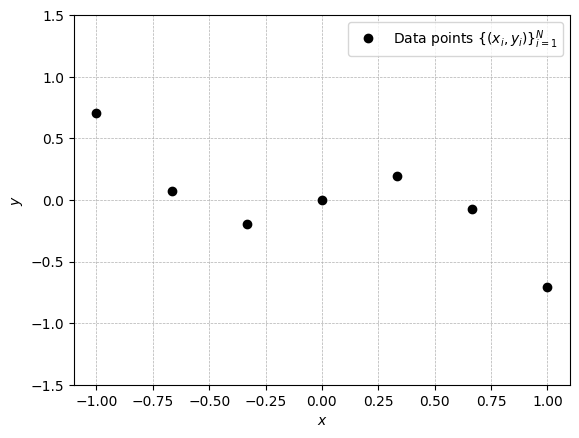

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

N = 7 # the number of data points
xs = np.linspace(-1, 1, num=N) # the x_i's
ys = np.sin(5*xs)*np.exp(np.abs(2*xs)) / 10 # the y_i's

fig, axes = plt.subplots(dpi=100)
axes.plot(xs,ys,'ko')
axes.legend([r'Data points $\{(x_{i},y_{i})\}_{i=1}^{N}$'])
axes.set_xlabel('$x$')
axes.set_ylabel('$y$')
axes.grid(linestyle='dashed', linewidth=0.5)
axes.set_ylim([-1.5, 1.5]);

We wish to fit a polynomial model $m(\cdot;\theta)$ of degree $n=3$ (overdetermined) and $n=9$ (underdetermined) to the data points  $\{(x_{i},y_{i})\}_{i=1}^{N}$ by solving optimization problem (1) or equivalently (2) in __Exercise 1__ above.

---
__a)__ First, do this by implementing the GD method. The GD method is given by
- Pick $\theta_{0}\in\mathbb{R}^{n+1}$
- For $k\geq 0$:
    - Set $\theta_{k+1} = \theta_{k} - \gamma_{k} \nabla f(\theta_{k})$ for some $\gamma_{k}>0$.

Pick $\theta_{0} = 0$ as the initial point, and try the constant step size

1. $\gamma_{k} = 1 / \beta$,

and run for $10^5$ iterations. Here, $\beta$ is the smoothness parameter from __Exercise 1__ above. Plot, in log-linear scale, both

- $f(\theta_{k})-f(\theta^{*})$ and
- $f(\overline{\theta}_{k})-f(\theta^{*})$ where $\overline{\theta}_{k} = \frac{1}{k+1}\sum_{l=0}^{k}\theta_{l}$, (Hint: use [sequential average computation](https://math.stackexchange.com/questions/106313/regular-average-calculated-accumulatively))

as a function of iteration number $k$. Give comments:
- Describe any difference between the $n=3$ (overdetermined) and $n=9$ (underdetermined) cases.

_Hint:_ What is $f(\theta^{*})$ in the overdetermined and underdetermined case, respectively?

__Solution:__

_Fill in your solution here!_

In the code we assign two diffrent values to f($θ^*$). In the underparameterized case we use the expression derived in task one and for the overparameterized case f($θ^*$) will be equal to zero. For the underparameterized case we can expect f($\theta^*$)to be postive (since a squared norm must be grater or equal to zero) which also is the case above if one look at the print for  f($θ^*$) = $2.6e^{-3}$. This holds since a qubic (n=3) function cannot interpolate the the data set of N data points. In the plots below, one can obtain that the underparameterized case converge faster to machine-precision. The difference in convergence rate is related to the eignevalue distributon of the Hessian for each case. The running avreage is diffrent for each case, mainly because it is correlated to the update of θ which depends on the eigenvalues as discussed above.

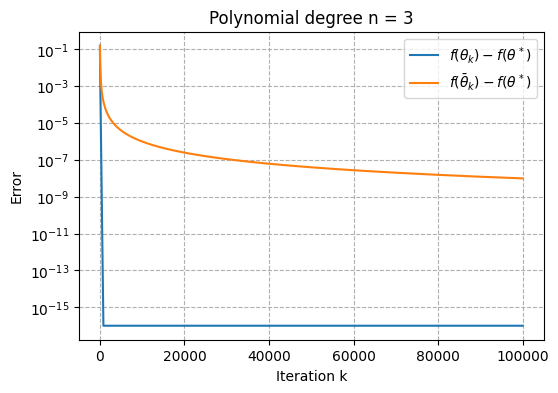

n = 3: beta = 2.4494e+00, f(theta*) = 2.0580e-03


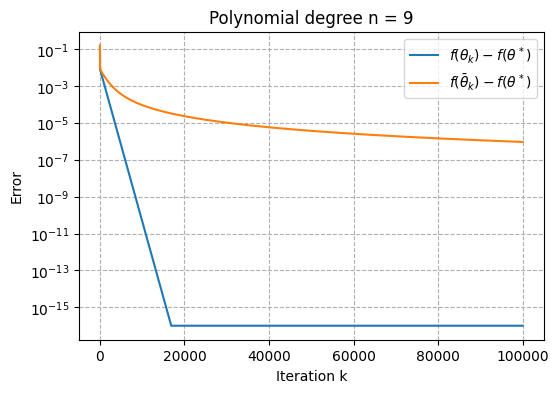

n = 9: beta = 3.6087e+00, f(theta*) = 0.0000e+00


In [ ]:

def gd_fit(n,xs,ys, max_iter):


  X = np.array([xs**i for i in range (n+1)]).T # Each row corrsponds to one xs value, i.e x_1^1, x_1^2 and so on, the next row is x_2^1,x_2^2..
  #print(X)
  Hess = (2/len(ys))*X.T@X # The hessian is given from task 1
  beta = np.linalg.eigvalsh(Hess)[-1] # To get the right beta, -1 to get the largest eigenvalue which is the beta
  gamma_k = 1/beta

  def f(theta): # (1/N) * ||X theta - ys||^2
    res = X @ theta -ys  # this is the X theta - ys, res: N*1
    return np.sum(res**2)/len(ys) # take the square and just take the sum over the colonn vector

  def grad_f(theta): # gradf(theta) = (2/N) X^T (X theta - ys)
    return 2/(len(ys))*X.T@(X@theta -ys)

  if n +1 < len(ys): # Under parameterized, the solution follows from task 1
    theta_opt = np.linalg.inv(X.T @ X) @ X.T @ ys
    f_opt = f(theta_opt)

  else:   # the minimum is theoretically zero for overparameterized
    f_opt = 0.0

  theta= np.zeros(n+1) # initial
  theta_sum = np.zeros(n+1) # it is a vector since we have n+1 paramters, one for each feature map
  errors = []
  error_avg =[]


  for k in range(max_iter):
    theta_sum +=theta # Update the values
    theta_avg = theta_sum/(k+1)
    errors.append(f(theta)-f_opt)
    error_avg.append(f(theta_avg)-f_opt) # append the errors as give

    theta = theta - gamma_k*grad_f(theta) # take a step
  return np.arange(max_iter), np.array(errors), np.array(error_avg), beta, f_opt # Want to convert to arrays when use for plotting

for n in [3, 9]: # the spec values
    k, errors, error_avg, beta, f_star = gd_fit(n, xs, ys, 10**5) # k is now an array of 0,1,2...

    plt.figure(figsize=(6, 4))
    plt.semilogy(k, np.maximum(errors, 1e-16), label=r"$f(\theta_k)-f(\theta^*)$") # We take the maximum to avoid the 0 case
    plt.semilogy(k, np.maximum(error_avg, 1e-16), label=r"$f(\bar{\theta}_k)-f(\theta^*)$")

    plt.title(f"Polynomial degree n = {n}")
    plt.xlabel("Iteration k")
    plt.ylabel("Error")
    plt.grid(True, linestyle="dashed")
    plt.legend()
    plt.show()

    print(f"n = {n}: beta = {beta:.4e}, f(theta*) = {f_star:.4e}")




---
__b)__ Next, do this by implementing the SGD method. The SGD method is given by
- Pick $\theta_{0}\in\mathbb{R}^{n+1}$
- For $k\geq 0$:
    - Pick $i\in\{1,\ldots,N\}$ uniformly at random
    - Set $\theta_{k+1} = \theta_{k} - \gamma_{k} \nabla f_{i}(\theta_{k})$ for some $\gamma_{k}>0$.

Pick $\theta_{0} = 0$ and try the step sizes

1. $\gamma_{k} = \frac{0.1}{\beta}$,
2. $\gamma_{k} = \frac{0.1}{\beta(k+1)}$,
3. $\gamma_{k} = \frac{0.1}{\beta(\lfloor k/1000\rfloor+1)}$, where $\lfloor \cdot \rfloor$ is the floor function,

and run for $10^5 N$ iterations. Plot, in log-linear scale, both

- $f(\theta_{k})-f(\theta^{*})$ and
- $f(\overline{\theta}_{k})-f(\theta^{*})$ where $\overline{\theta}_{k} = \frac{1}{k+1}\sum_{l=0}^{k}\theta_{l}$,

as a function of iteration number $k$. Give comments:
- Does the step sizes matter?
- Is there a difference between the $n=3$ (overdetermined) and $n=9$ (underdetermined) cases.
- Which combination worked best?
- Which combination of $\gamma_{k}$ and $n$ (i.e. overdetermined or underdetermined) corresponds the most to training of neural networks? This question qualitative and has no unique answer.

__Solution:__
As can be seen in the plots below the step size matters a lot for the convergence rate. Since we are randomly selecting a data point $x_i$ for each iteration, the gradient becomes noisy and hence the different values for $\theta_{k+1}$ too. Hence, $f(\theta_k)-f(\theta^*)$ fluctuate, even if the algorithm is making progress towards a smaller loss. This is especially obvious in the first plot below, where the step size is constant during the entire epoch, making the oscillations persist. If we instead decrease the stepsize the noise from the randomly selected data points will be subpressed and the oscilliations would gradually become smaller, which is the case in plot 2 below. However, the trade-off is that the progress becomes slower, which is also clear in the plot. For the third plot, the step size decreases every 1000 iterations, therefore the oscillations may reduce in stages, which is the case in the plot aswell. Since $f(\theta_k\hat) -f(\theta^*)$ is decreasing for the plots, we can confirm that the  is making progress.  

For n =3 $f(\theta^*)>0$  (from task 1). At the optimum $ ∇f(\theta^*)=0$ but every singel gradient $∇f_i(θ^*)$ does not have to be zero. Therefore the model can reach reach an fluctuating region and the solution does not converge exactly to zero. However, by reducing the step size this fluctuations can decrease. For n=9, the model can interpolate and find an exact solution. Therefore, for every i the gradient can be $∇f_i(θ^*)=0$. Hence, the noise vanishes at the solution and we do not need to reduce the step size. This is confirmed in the fourth plot below. This is also the best combination because we reach the smallest errors in the least number of iterations. By decreasing the step size when n=9 will just slow down the convergence. This is confirmed by plot 5 and 6.

Since many neural networks have more parameters than sampels this corresponds to n=9. You often implement some kind of step decay, which may correspond to the third formula for the step-size decay in the instructions.

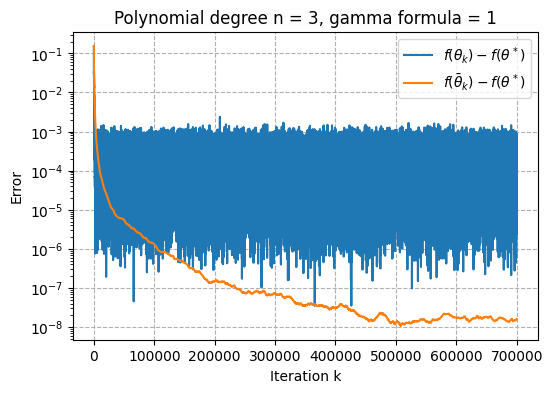

n = 3, gamma formula = 1: beta = 2.4494e+00, f(theta*) = 2.0580e-03


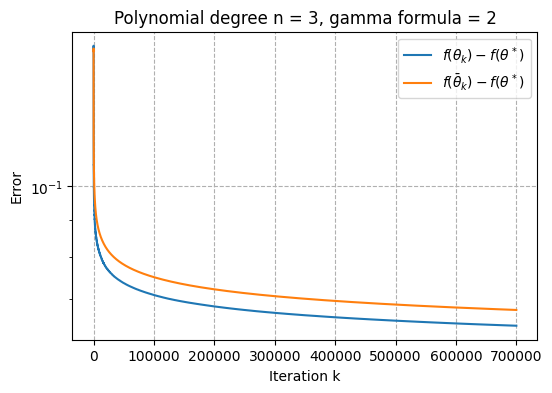

n = 3, gamma formula = 2: beta = 2.4494e+00, f(theta*) = 2.0580e-03


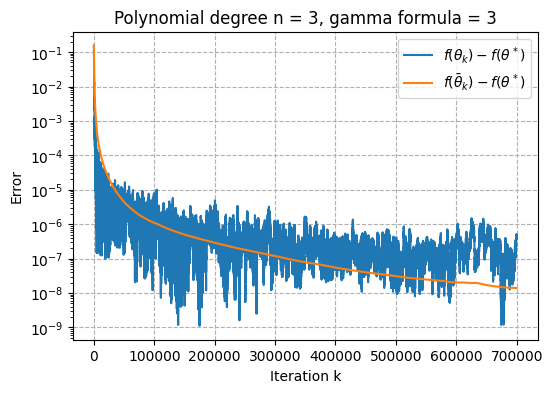

n = 3, gamma formula = 3: beta = 2.4494e+00, f(theta*) = 2.0580e-03


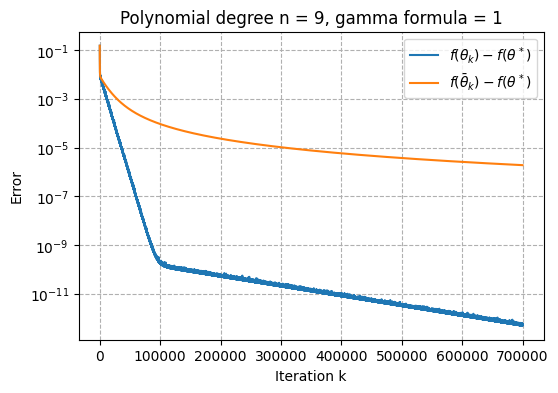

n = 9, gamma formula = 1: beta = 3.6087e+00, f(theta*) = 0.0000e+00


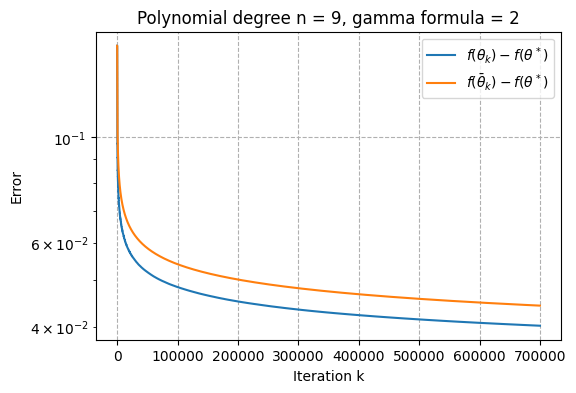

n = 9, gamma formula = 2: beta = 3.6087e+00, f(theta*) = 0.0000e+00


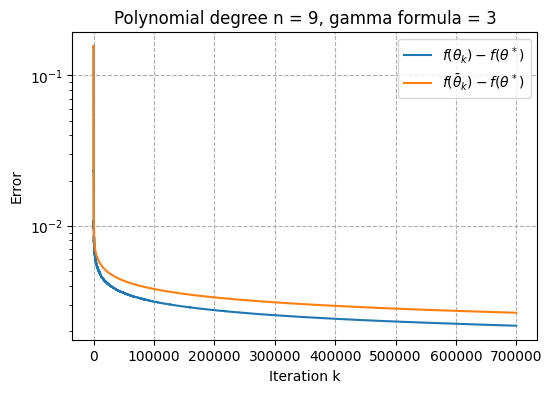

n = 9, gamma formula = 3: beta = 3.6087e+00, f(theta*) = 0.0000e+00


In [ ]:

def sgd_fit(n,xs,ys, max_iter, gamma_testNbr):

  N = len(ys)
  X = np.array([xs**i for i in range (n+1)]).T # Each row corrsponds to one xs value, i.e x_1^1, x_1^2 and so on, the next row is x_2^1,x_2^2..
  #print(X)
  Hess = (2/len(ys))*X.T@X # The hessian is given from task 1
  beta = np.linalg.eigvalsh(Hess)[-1] # To get the right beta, -1 to get the largest eigenvalue which is the beta



  def f(theta): # (1/N) * ||X theta - ys||^2
    res = X @ theta -ys  # this is the X theta - ys, res: N*1
    return np.sum(res**2)/N # take the square and just take the sum over the colonn vector

  def grad_fi(theta,i): # gradf_i(theta) = 2 (theta.t*psi(x-i) - u_i)*psi(x-i) from task 1
    return 2*(theta.T@X[i,:]-ys[i])*X[i,:]

  if n +1 < N: # Under parameterized, the solution follows from task 1
    theta_opt = np.linalg.inv(X.T @ X) @ X.T @ ys
    f_opt = f(theta_opt)

  else:   # the minimum is theoretically zero for overparameterized
    f_opt = 0.0

  theta= np.zeros(n+1) # initial
  theta_sum = np.zeros(n+1) # it is a vector since we have n+1 paramters, one for each feature map
  errors = []
  error_avg =[]


  for k in range(max_iter):
    i = np.random.randint(N) # Pick i uniformly at random, 0->N-1 (zero index)
    if gamma_testNbr ==1:
      gamma = 0.1/beta # The diffrent formulas for gamma from the instructions
    elif gamma_testNbr == 2:
      gamma = 0.1/(beta*(k+1))
    elif gamma_testNbr == 3:
      gamma = 0.1/(beta*(k//1000 +1))

    theta_sum +=theta # Update the values
    theta_avg = theta_sum/(k+1)
    errors.append(f(theta)-f_opt)
    error_avg.append(f(theta_avg)-f_opt) # append the errors as give

    theta = theta - gamma*grad_fi(theta,i) # take a step
  return np.arange(max_iter), np.array(errors), np.array(error_avg), beta, f_opt # Want to convert to arrays when use for plotting

for n in [3, 9]:  # the spec values
    for gamma_test in [1, 2, 3]:  # the three step-sizes

        k, errors, error_avg, beta, f_star = sgd_fit(n, xs, ys,N*10**5, gamma_test)

        plt.figure(figsize=(6, 4))
        plt.semilogy(k, np.maximum(errors, 1e-16),
                     label=r"$f(\theta_k)-f(\theta^*)$")
        plt.semilogy(k, np.maximum(error_avg, 1e-16),
                     label=r"$f(\bar{\theta}_k)-f(\theta^*)$")

        plt.title(f"Polynomial degree n = {n}, gamma formula = {gamma_test}")
        plt.xlabel("Iteration k")
        plt.ylabel("Error")
        plt.grid(True, linestyle="dashed")
        plt.legend()
        plt.show()

        print(f"n = {n}, gamma formula = {gamma_test}: "
              f"beta = {beta:.4e}, f(theta*) = {f_star:.4e}")




---
### Exercise 3: Fitting points in $\mathbb{R}$ using fully connected feedforward neural networks

Again, we consider the data points $\{(x_{i},y_{i})\}_{i=1}^{N}\subseteq\mathbb{R}\times\mathbb{R}$, where $N=7$, below:


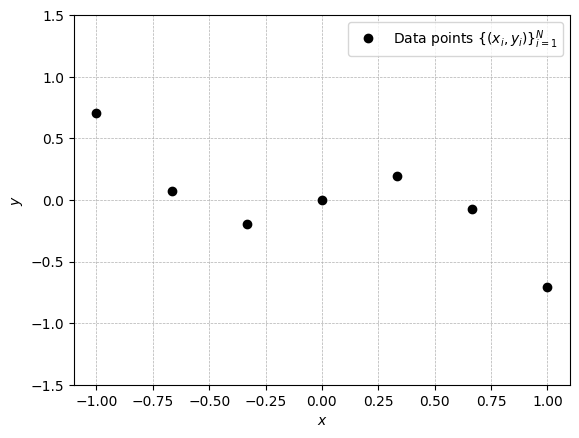

In [ ]:
N = 7 # the number of data points
xs = np.linspace(-1, 1, num=N) # the x_i's
ys = np.sin(5*xs)*np.exp(np.abs(2*xs)) / 10 # the y_i's

fig, axes = plt.subplots(dpi=100)
axes.plot(xs,ys,'ko')
axes.legend([r'Data points $\{(x_{i},y_{i})\}_{i=1}^{N}$'])
axes.set_xlabel('$x$')
axes.set_ylabel('$y$')
axes.grid(linestyle='dashed', linewidth=0.5)
axes.set_ylim([-1.5, 1.5]);

Polynomial fitting as in __Exercise 1__ and __Exercise 2__ gives:

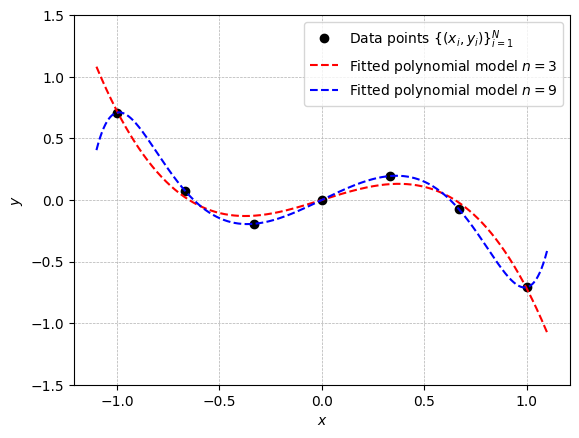

In [ ]:
theta_star_n_9 = np.array([0,  0.8, 0, -1.9, 0, -0.583957507, 0, 0.28, 0, 0.695322536])
theta_star_n_3 = np.array([0,  0.523557283,  0, -1.24520755])
x = np.linspace(-1.1, 1.1, num = 1000)

fig, axes = plt.subplots(dpi=100)
axes.plot(xs,ys,'ko')
axes.plot(x, np.polyval(np.flip(theta_star_n_3), x),'r--')
axes.plot(x, np.polyval(np.flip(theta_star_n_9), x),'b--')
axes.legend([r'Data points $\{(x_{i},y_{i})\}_{i=1}^{N}$', r'Fitted polynomial model $n=3$', r'Fitted polynomial model $n=9$'])
axes.set_xlabel('$x$')
axes.set_ylabel('$y$')
axes.grid(linestyle='dashed', linewidth=0.5)
axes.set_ylim([-1.5, 1.5]);

In this exercise, we are going to explore fitting of these data points using fully connected feedforward neural networks. We will do this by considering the problem

$$
\begin{align}\label{eq:3}\tag{3}
		\underset{\theta}{\mathrm{minimize}} \frac{1}{N}\sum_{i=1}^N L(m(x_i;\theta),y_i)
\end{align}
$$

where $L:\mathbb{R}\times\mathbb{R}\rightarrow\mathbb{R}$ is the least squares loss, i.e.

$$
\begin{align*}
L(u,y) = (u-y)^{2}
\end{align*}
$$

for each $u,y\in\mathbb{R}$ and $m(\cdot;\theta):\mathbb{R}\rightarrow\mathbb{R}$ is a fully connected feedforward neural network model, i.e.

$$
\begin{align*}
m(x;\theta) = W_{D}\sigma_{D-1}(W_{D-1}\sigma_{D-2}(...\sigma_1(W_1 x + b_{1})...)+b_{D-1})+b_{D}
\end{align*}
$$

for each $x\in\mathbb{R}$, where $\sigma_i$ is an activation functions that act elements-wise, for each $i=1,\ldots,D-1$, and

$$
\begin{align*}
    \theta = (W_{1},b_1,\ldots,W_{D},b_{D})
\end{align*}
$$

such that

$$
\begin{align*}
    \begin{cases}
        W_{1}\in\mathbb{R}^{f_{1} \times 1}& \text{ and }\quad b_{1} \in\mathbb{R}^{f_1}\\
        W_{i}\in\mathbb{R}^{f_{i} \times f_{i-1}}& \text{ and }\quad b_{i} \in\mathbb{R}^{f_i} \quad\text{ for }\quad i=2,\ldots,D-1 \\
        W_{D}\in\mathbb{R}^{1 \times f_{D-1}}& \text{ and }\quad b_{D} \in\mathbb{R}.
    \end{cases}
\end{align*}
$$

In particular, we will study how the trained model $m(\cdot;\theta)$ depends on:
- The widths ($f_{i}$) and depth ($D$)
- Different activation functions ($\sigma_{i}$)
- Different initial points $\theta_{0}$ used in training
- Different training algorithms such as SGD and and Adam

We will also study:
- How the loss landscape of (3) looks along different directions at an "optimal point" of (3). (Note that we in general have no guarantees that our optimization algorithms will reach a true optimal point of (3) since the problem in nonconvex in general.)

_Remark:_
We will train the models using `pytorch`. `pytorch` is a widely used library or *module* for doing machine learning in python.
It allows the user to construct, train and evaluate neural networks.

- You will need to [install](https://anaconda.org/pytorch/pytorch) `pytorch`

Take a quick look at `pytorch`'s
- [tutorials](https://pytorch.org/tutorials/)
- [documentation](https://pytorch.org/docs/stable/index.html)

---
`pytorch` expects to get data from a `DataLoader` object. Below we create a `DataLoader` and provide it with our data:

In [ ]:
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset
from torch.utils.data import DataLoader
from torch import optim

torch_xs = torch.tensor(xs.reshape((N,1)), dtype=torch.float32)
torch_ys = torch.tensor(ys.reshape((N,1)), dtype=torch.float32)
dataset = TensorDataset(torch_xs, torch_ys)
data_loader = DataLoader(dataset, batch_size=len(xs)) # other batch sizes are of course allowed

Typically in `pytorch`, models are defined as a child of the `nn.Module` class. Below, we create a model with:
- Depth $D=2$
- Width $f_1=10$
- ReLU as activation function

In [ ]:
class model(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear1 = nn.Linear(in_features=1, out_features=10)
        self.linear2 = nn.Linear(in_features=10, out_features=1)

    def forward(self, x):
        x = self.linear1(x)
        x = F.relu(x)
        x = self.linear2(x)
        return x

# Create an instance of the model class.
model = model()

In machine learning, the objective function in (3) is sometimes itself called a loss function. In fact, it is already [implemented](https://pytorch.org/docs/stable/generated/torch.nn.MSELoss.html) in `pytorch` and we create the corresponding loss function object below:

In [ ]:
loss_fn = nn.MSELoss()

`torch.optim` is a `pytorch` package implementing various optimization algorithms. Below we create an optimizer object that allows us to take a SGD step with step-size/learning rate equal to $0.05$.

In [ ]:
optimizer = optim.SGD(model.parameters(), lr=0.05)

Once we have defined the data loader, the model, the loss function and the optimizer as above, we can train the network by simply following these steps in a loop:
1. Sample a batch of data from our dataset
2. Compute the model's prediction on the batch
3. Compute the loss of the prediction w.r.t. ground-truth
4. Backpropagate the loss through the model's parameters
5. Perform one training step.

We will do this for $2000$ epochs.

In [ ]:
for epoch in range(2000):
    losses_in_epoch = []
    for batch in data_loader:

        # 1. These are the sampled batches of inputs and ground-truth
        batch_x, batch_y = batch

        # 2. Compute the model's prediction on the batch
        pred = model(batch_x)

        # 3. Compute the loss of the prediction w.r.t. ground-truth
        loss = loss_fn(pred, batch_y)

        # Save losses in a list for averaging later (not sctrictly necessary for batch_size = len(x))
        losses_in_epoch.append(loss)

        # 4. Backpropagation
        loss.backward()

        # 5. One step of SGD
        optimizer.step()

        # Zero the gradients computed in the backpropagation, for starting new optimization step
        optimizer.zero_grad()

    # Every 100th epoch, display progress
    if epoch % 100 == 0:
        print('Epoch: {}\tLoss: {}'.format(epoch, sum(losses_in_epoch)/len(losses_in_epoch)))

Epoch: 0	Loss: 0.08477546274662018
Epoch: 100	Loss: 0.059954140335321426
Epoch: 200	Loss: 0.048661161214113235
Epoch: 300	Loss: 0.039291687309741974
Epoch: 400	Loss: 0.032317522913217545
Epoch: 500	Loss: 0.026019949465990067
Epoch: 600	Loss: 0.020486855879426003
Epoch: 700	Loss: 0.01573886163532734
Epoch: 800	Loss: 0.011788261123001575
Epoch: 900	Loss: 0.008640691637992859
Epoch: 1000	Loss: 0.006231202278286219
Epoch: 1100	Loss: 0.0044433423317968845
Epoch: 1200	Loss: 0.0031437312718480825
Epoch: 1300	Loss: 0.0022103688679635525
Epoch: 1400	Loss: 0.0015450154896825552
Epoch: 1500	Loss: 0.0010735285468399525
Epoch: 1600	Loss: 0.0007415014551952481
Epoch: 1700	Loss: 0.0005092728533782065
Epoch: 1800	Loss: 0.00034801827860064805
Epoch: 1900	Loss: 0.00023684653569944203


Below we plot trained model:

Traing loss: 0.00016


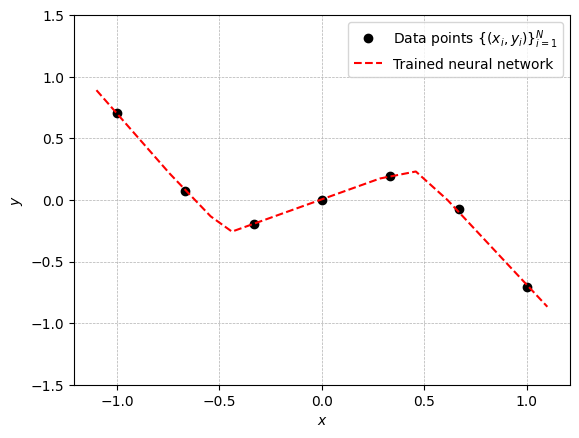

In [ ]:
with torch.no_grad():
    x = np.linspace(-1.1, 1.1, num = 1000)
    torch_x = torch.tensor(x.reshape((1000,1)), dtype=torch.float32)
    y_pred = model(torch_x).numpy()

    fig, axes = plt.subplots(dpi=100)
    axes.plot(xs,ys,'ko')
    axes.plot(x, y_pred,'r--')
    axes.legend([r'Data points $\{(x_{i},y_{i})\}_{i=1}^{N}$', r'Trained neural network'])
    axes.set_xlabel('$x$')
    axes.set_ylabel('$y$')
    axes.grid(linestyle='dashed', linewidth=0.5)
    axes.set_ylim([-1.5, 1.5]);

    print("Traing loss: {:.5f}".format(loss_fn(model(torch_xs),torch_ys).item()))

__a)__ First, we experiment with the widths ($f_{i}$) and depth ($D$).

Choose widths ($f_{i}$) and depth ($D$) such that:
- the network becomes underparameterized (motive why it is underparameterized)
- the network becomes overparameterized (motive why it is overparameterized)

and train the model as above.

In this subproblem, keep the activation functions fixed as ReLU. However, you are free to experiment with the learning rate and the number of epoch.

How does these two cases differ? Give a qualitative and quantitative analysis.

__Solution:__

_Fill in your solution here!_

For the small model we used depth 2, with width 1. Therefore the number of parameters are 2+2=4 (biases for each node). Since the number of data points are 7, this is underparameterized. For the other model the depth is 2, but the width is 8. This gives 8+8+8+1=25 parameters. Hence the model is overparameterized. The traing loss for each epoch is plotted below, and the final training loss is printed avbove the plot for each of the two models. Both the plot and the prints indicates that larger model (width=8) has a lower loss and hence the model fit the data more accurately. In the first plot below the loss for the smaller reaches a plateau while the larger models loss have not converged yet.  It is worth mention that the traningloss can be low but the model may not be able to generalize well.

For the smaller model, there is only one hidden neuron with a ReLu activation function. Therefore, the fitted function is pice wise linear with just one change in slope, this can also be seen in the middle plot below. However, the larger model can combine 10 activation functions and represent a more complex function, with more changes in slope. This is shown in the third plot below.

Epoch: 0	Loss: 0.28329646587371826
Epoch: 100	Loss: 0.07067755609750748
Epoch: 200	Loss: 0.06978262215852737
Epoch: 300	Loss: 0.06899942457675934
Epoch: 400	Loss: 0.06832312792539597
Epoch: 500	Loss: 0.0677545815706253
Epoch: 600	Loss: 0.06728866696357727
Epoch: 700	Loss: 0.06691582500934601
Epoch: 800	Loss: 0.06662389636039734
Epoch: 900	Loss: 0.06639979779720306
Epoch: 1000	Loss: 0.06623078882694244
Epoch: 1100	Loss: 0.06610528379678726
Epoch: 1200	Loss: 0.06601337343454361
Epoch: 1300	Loss: 0.06594683229923248
Epoch: 1400	Loss: 0.06589914858341217
Epoch: 1500	Loss: 0.06586527824401855
Epoch: 1600	Loss: 0.06584138423204422
Epoch: 1700	Loss: 0.06582464277744293
Epoch: 1800	Loss: 0.06581296771764755
Epoch: 1900	Loss: 0.0658048763871193
Epoch: 0	Loss: 0.22092559933662415
Epoch: 100	Loss: 0.0551077164709568
Epoch: 200	Loss: 0.046641238033771515
Epoch: 300	Loss: 0.039276622235774994
Epoch: 400	Loss: 0.034233421087265015
Epoch: 500	Loss: 0.03039027750492096
Epoch: 600	Loss: 0.0269460659474

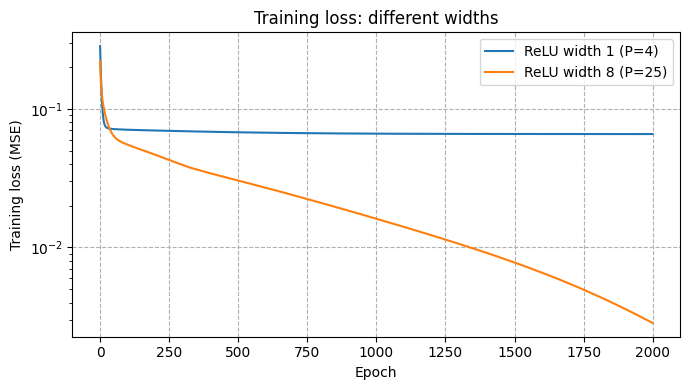

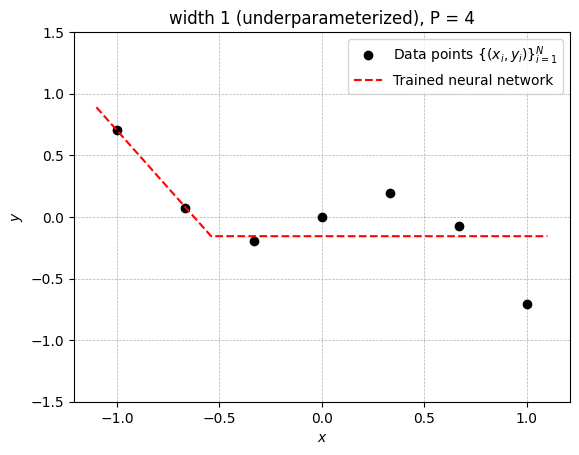

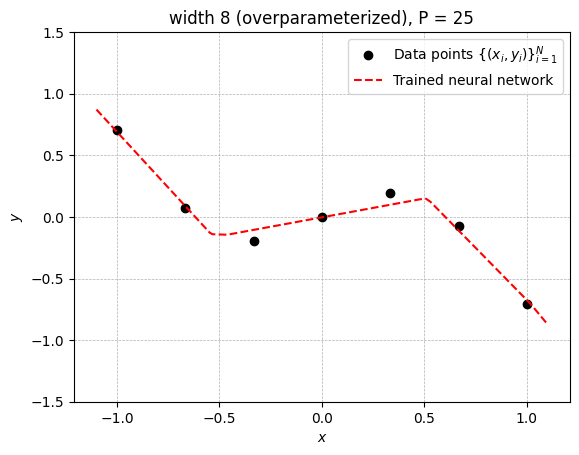

In [ ]:
class Model(nn.Module):
    def __init__(self, width,activation): # the same as above, but now easier to change width and activation function
        super().__init__()
        self.linear1 = nn.Linear(in_features=1, out_features=width)
        self.linear2 = nn.Linear(in_features=width, out_features=1)
        self.activation= activation

    def forward(self, x):
        x = self.linear1(x)
        x = self.activation(x)
        x = self.linear2(x)
        return x

def count_params(m):
    return sum(p.numel() for p in m.parameters()) # p.numel counts the total nbr of nmr in the tensor p which is the parameters

# Create instances of the model clas
model_s = Model(width=1,activation=nn.ReLU() ) # small model
model_l = Model(width=8, activation=nn.ReLU()) # larger model
optimizer_s = optim.SGD(model_s.parameters(), lr=0.05)
optimizer_l = optim.SGD(model_l.parameters(), lr=0.05)


def train(model, opt, epoch):
  history = [] # For plotting
  for epoch in range(epoch):
      losses_in_epoch = []
      for batch in data_loader:

          # 1. These are the sampled batches of inputs and ground-truth
          batch_x, batch_y = batch

          # 2. Compute the model's prediction on the batch
          pred = model(batch_x)

          # 3. Compute the loss of the prediction w.r.t. ground-truth
          loss = loss_fn(pred, batch_y)

          # Save losses in a list for averaging later (not sctrictly necessary for batch_size = len(x))
          losses_in_epoch.append(loss.item())

          # 4. Backpropagation
          loss.backward()

          # 5. One step of SGD
          opt.step()

          # Zero the gradients computed in the backpropagation, for starting new optimization step
          opt.zero_grad()

      avg_loss = sum(losses_in_epoch) / len(losses_in_epoch)
      history.append(avg_loss)

      # Every 100th epoch, display progress
      if epoch % 100 == 0:
        print('Epoch: {}\tLoss: {}'.format(epoch, avg_loss))

  return history

hist_s=train(model_s, optimizer_s, 2000) # Want this for plotting
hist_l=train(model_l, optimizer_l,2000)
print(f"width 1  (model_s): P = {count_params(model_s)}, final training loss = {hist_s[-1]}")
print(f"width 10 (model_l): P = {count_params(model_l)}, final training loss = {hist_l[-1]}")

def plot_loss(hist1, hist2, model1, model2, label1, label2, title):
    plt.figure(figsize=(7, 4))

    plt.semilogy(hist1, label=f"{label1} (P={count_params(model1)})")
    plt.semilogy(hist2, label=f"{label2} (P={count_params(model2)})")

    plt.xlabel("Epoch")
    plt.ylabel("Training loss (MSE)")
    plt.title(title)
    plt.grid(True, linestyle="dashed")
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_loss(hist_s, hist_l, model_s, model_l, "ReLU width 1", "ReLU width 8","Training loss: different widths")

def plot_func(model,title=""): # plotting the func and the model
  with torch.no_grad():
    x = np.linspace(-1.1, 1.1, num = 1000)
    torch_x = torch.tensor(x.reshape((1000,1)), dtype=torch.float32)
    y_pred = model(torch_x).numpy()

    fig, axes = plt.subplots(dpi=100)
    axes.plot(xs,ys,'ko')
    axes.plot(x, y_pred,'r--')
    axes.legend([r'Data points $\{(x_{i},y_{i})\}_{i=1}^{N}$', r'Trained neural network'])
    axes.set_xlabel('$x$')
    axes.set_ylabel('$y$')
    axes.set_title(title)
    axes.grid(linestyle='dashed', linewidth=0.5)
    axes.set_ylim([-1.5, 1.5]);

plot_func(model_s, f"width 1 (underparameterized), P = {count_params(model_s)}")
plot_func(model_l, f"width 8 (overparameterized), P = {count_params(model_l)}")


__b)__ Second, we will try out different activation functions ($\sigma_{i}$).

Train two overparameterized networks with the same widths and depth, using
- ReLU activation at each layer for one of the networks, and
- 4 * sigmod activation at each layer for the other network.

You are free to experiment with the learning rate and the number of epoch.

How does these two cases differ? Give a qualitative and quantitative analysis.

__Solution:__

We run the test for 3000 epochs and the training loss for epoch is plotted below. The ReLu network achives a lower traning loss, which can be seen in both the print below, but also in the plot. The scaled sigma network, performs worse with a higher traning loss (see the print). As mentioned above, ReLu is piecewise linear and has a constant gradient of 1 for positive inputs. This may help the optimization. The sigmoid function is instead smooth and gradients can become small for large positive or negative inputs. This may slow down the learning and a worse training loss. Multiplying by 4 just scales the output and gradients. As can be seen in plot two and 3 below, the ReLu function generates a linear function, while the sigmoid model generates a smooth function. The ReLu provides a better fit for the data points in the plots below, while the sigmoid function does not fit the datapoints as good. The reason may be the saturation of the training for the sigmoid function as decribed above.

Epoch: 0	Loss: 0.16452434659004211
Epoch: 100	Loss: 0.06522468477487564
Epoch: 200	Loss: 0.060668766498565674
Epoch: 300	Loss: 0.057489220052957535
Epoch: 400	Loss: 0.05571902170777321
Epoch: 500	Loss: 0.05431535467505455
Epoch: 600	Loss: 0.05327124148607254
Epoch: 700	Loss: 0.05248108506202698
Epoch: 800	Loss: 0.05184938758611679
Epoch: 900	Loss: 0.05132930725812912
Epoch: 1000	Loss: 0.0508972592651844
Epoch: 1100	Loss: 0.05051705986261368
Epoch: 1200	Loss: 0.05019639804959297
Epoch: 1300	Loss: 0.049911029636859894
Epoch: 1400	Loss: 0.049217816442251205
Epoch: 1500	Loss: 0.04814163222908974
Epoch: 1600	Loss: 0.0463276244699955
Epoch: 1700	Loss: 0.043451957404613495
Epoch: 1800	Loss: 0.03900260850787163
Epoch: 1900	Loss: 0.03233746811747551
Epoch: 2000	Loss: 0.02706264518201351
Epoch: 2100	Loss: 0.021820303052663803
Epoch: 2200	Loss: 0.017000099644064903
Epoch: 2300	Loss: 0.012900679372251034
Epoch: 2400	Loss: 0.009696186520159245
Epoch: 2500	Loss: 0.007360223680734634
Epoch: 2600	Loss

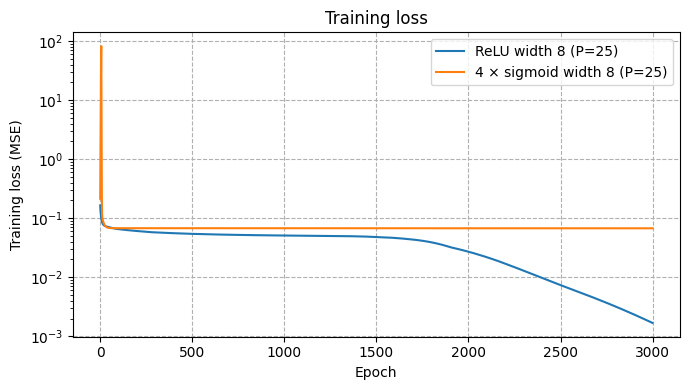

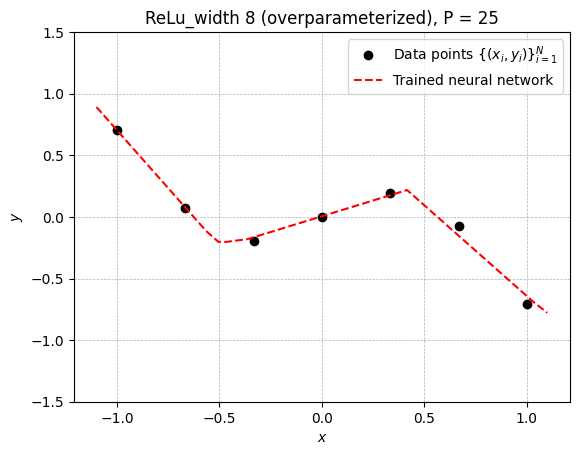

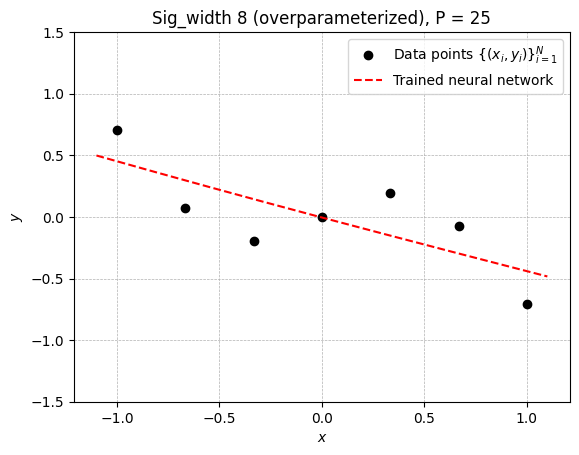

In [ ]:
class FourSigmoid(nn.Module):
    def forward(self, x):
        return 4 * nn.functional.sigmoid(x) # This is how we construct 4*sigmoid

model_ReLu = Model(width=8,activation=nn.ReLU() ) # the Relu layer!
model_sig = Model(width=8, activation=FourSigmoid()) # the sigmoid

optimizer_ReLu = optim.SGD(model_ReLu.parameters(), lr=0.05)
optimizer_sig = optim.SGD(model_sig.parameters(), lr=0.05)

hist_ReLu=train(model_ReLu, optimizer_ReLu, 3000) # Train for 3000 epochs
hist_sig=train(model_sig, optimizer_sig,3000)

print(f"width 8  ReLu: P = {count_params(model_ReLu)}, final training loss = {hist_ReLu[-1]}")
print(f"width 8 Sig: P = {count_params(model_sig)}, final training loss = {hist_sig[-1]}")

plot_loss(hist_ReLu, hist_sig, model_ReLu, model_sig,"ReLU width 8", "4 × sigmoid width 8", "Training loss")
plot_func(model_ReLu, f"ReLu_width 8 (overparameterized), P = {count_params(model_ReLu)}")
plot_func(model_sig, f"Sig_width 8 (overparameterized), P = {count_params(model_sig)}")

__c)__ Third, we consider different initial points ($\theta_{0}$) used in training.


For an overparameterized network with ReLU activation functions at each layer and fixed widths and depth, train it with different initial point (note that the constructor of `nn.Module` will initialize the parameters randomly).

Does the initial point affect the final trained network? Give a qualitative and quantitative analysis.

__Solution:__

_Fill in your solution here!_

Since the constructor of `nn.Module` initialize the parameters randomly we simulate this exercise just by creating 5 different models in a for loop. For each new initialization of Model one will get new initial points ($\theta_{0}$). In the plot below, the trainingloss is plotted for each epoch, and we can conclude that diffrent initial points affect the trained network since they converge to diffrent final traningloss values. The final paramter values are also displayed and one can see that those differs to the initial values. The reason for this may be that loss functions of nueral networks often are non-convex. Thus, different initial points can give different solutions. The ReLu activation function can also cause different neruons to be active or not, depending or their weights and biases.

If one compare the functions plots below (one for each initialization) with the final parameter values, one can conclude that the parameters can be quite different but still generate similar functions plots. This is beacuse a neural network can represent similar input-output mappings with different parameters. One can also conclude that with a smaller traning loss, the function plot interpolates the datapoints better.  

Epoch: 0	Loss: 0.22459813952445984
Epoch: 100	Loss: 0.07684342563152313
Epoch: 200	Loss: 0.06819457560777664
Epoch: 300	Loss: 0.0664231926202774
Epoch: 400	Loss: 0.06445234268903732
Epoch: 500	Loss: 0.06195531412959099
Epoch: 600	Loss: 0.05861269682645798
Epoch: 700	Loss: 0.05487147718667984
Epoch: 800	Loss: 0.051520369946956635
Epoch: 900	Loss: 0.04808541014790535
Epoch: 1000	Loss: 0.04459143057465553
Epoch: 1100	Loss: 0.041055142879486084
Epoch: 1200	Loss: 0.03752899169921875
Epoch: 1300	Loss: 0.034067247062921524
Epoch: 1400	Loss: 0.03072531893849373
Epoch: 1500	Loss: 0.027531355619430542
Epoch: 1600	Loss: 0.02456553652882576
Epoch: 1700	Loss: 0.0218201931566
Epoch: 1800	Loss: 0.019324805587530136
Epoch: 1900	Loss: 0.017127832397818565
Epoch: 0	Loss: 0.35721468925476074
Epoch: 100	Loss: 0.06275949627161026
Epoch: 200	Loss: 0.06192968413233757
Epoch: 300	Loss: 0.061158839613199234
Epoch: 400	Loss: 0.06040731817483902
Epoch: 500	Loss: 0.059642501175403595
Epoch: 600	Loss: 0.0588415600

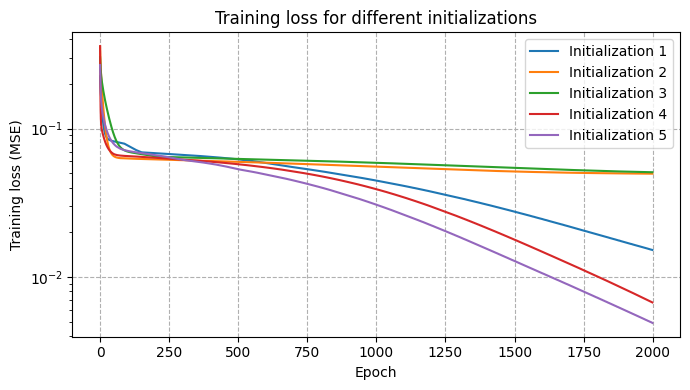


--- Run 1 ---
linear1.weight
Initial: tensor([[-0.6559],
        [-0.6555],
        [ 0.9464],
        [-0.5378],
        [-0.0901],
        [-0.8282],
        [ 0.5854],
        [-0.6759]])
Final:   tensor([[-0.6215],
        [-1.2191],
        [ 1.2924],
        [-0.5378],
        [-0.0901],
        [-0.9074],
        [ 0.9303],
        [-0.7495]])
linear1.bias
Initial: tensor([ 0.7240,  0.2302,  0.1064, -0.6962, -0.9612,  0.7472,  0.2878,  0.4632])
Final:   tensor([ 0.7517,  0.4155,  0.4324, -0.6962, -0.9612,  0.9075,  0.9328,  0.7512])
linear2.weight
Initial: tensor([[-0.2353,  0.0963,  0.2829, -0.1146, -0.0677, -0.0721, -0.2369,  0.1671]])
Final:   tensor([[ 0.2288, -1.0889,  1.0158, -0.1146, -0.0677,  0.6392, -1.1688,  0.6945]])
linear2.bias
Initial: tensor([0.2190])
Final:   tensor([-0.1701])

--- Run 2 ---
linear1.weight
Initial: tensor([[-0.0755],
        [-0.2150],
        [ 0.4986],
        [ 0.4411],
        [-0.5266],
        [ 0.5449],
        [-0.3128],
        [-0.5163

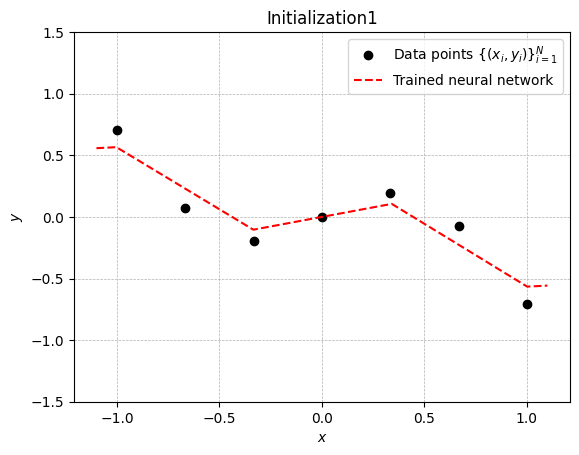

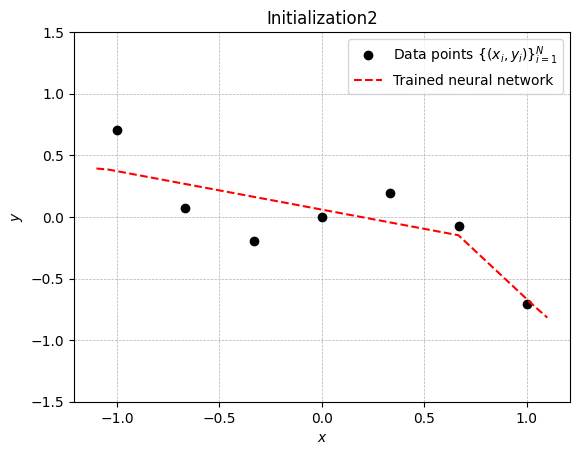

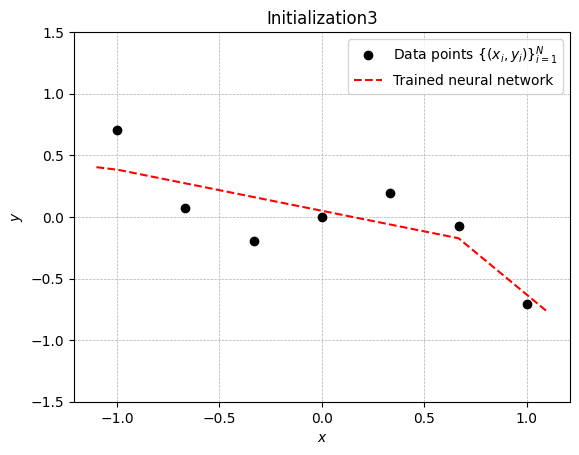

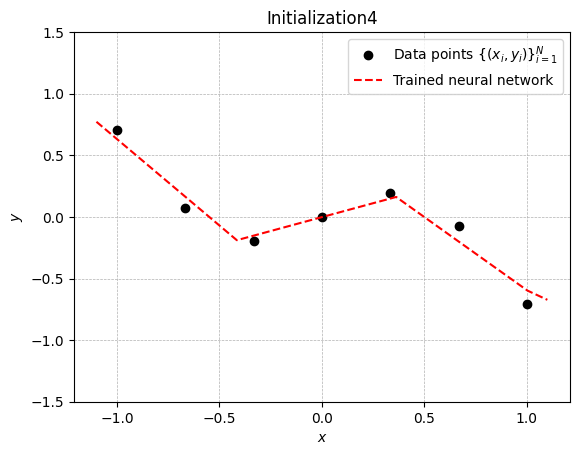

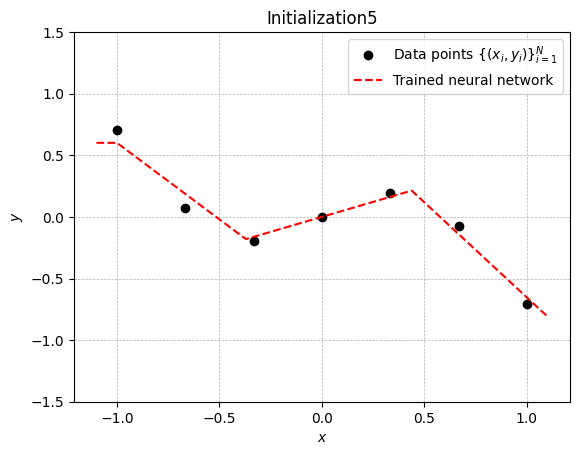

In [ ]:


# Write your code here

initial_params = [] # Save the intial paramaters for each model. should be 8 weights+8 biases + 8 weights + 1 bias = 25
models = [] # To save models
histories = []

for run in range(5): # test five different initial points
    model = Model(width=8, activation=nn.ReLU()) # this gives 5 diffrent models, with the same depth an width
    optimizer = optim.SGD(model.parameters(), lr=0.05)

    # save initial parameters
    initial_params.append({
        name: param.detach().clone() # This make a clone, so they the initial values does not change
        for name, param in model.named_parameters()
    })

    history = train(model, optimizer, 2000)

    models.append(model)
    histories.append(history)


plt.figure(figsize=(7, 4))# To plot the diffrent models and their loss

for i, history in enumerate(histories): # for each model we get the hisotry
    plt.semilogy(
        history,
        label=f"Initialization {i + 1}"
    )

plt.xlabel("Epoch")
plt.ylabel("Training loss (MSE)")
plt.title("Training loss for different initializations")
plt.grid(True, linestyle="dashed")
plt.legend()
plt.tight_layout()
plt.show()

# Compare initial and final parameters- given from instructions
for i, model in enumerate(models):
    print(f"\n--- Run {i + 1} ---")

    for name, param in model.named_parameters():
      if param.requires_grad:
        print(f"{name}")
        print("Initial:", initial_params[i][name])
        print("Final:  ", param.detach())# To see the paramters after training

for i,mod in enumerate(models): # plot the functions
  plot_func(mod,title=f"Initialization{i + 1}")

__d)__ Fourth, we consider different training algorithms.

Compare
- SGD, and
- Adam (`optimizer = optim.Adam(model.parameters(), lr=0.1)`)

for an overparameterized network with ReLU activation functions at each layer and fixed widths and depth.

You are free to experiment with the learning rates and the number of epoch.

How does these two cases differ? Give a qualitative and quantitative analysis.

__Solution:__

_Fill in your solution here!_

For this exercise we compered ADAM and SGD with the same depth, width and ReLu activation function. To just compere the effect of the optimizer, we used the same initial paramters and trained for the same number of epochs. SGD update parameters using gradient and a fixed larning rate. Adam instead uses a moving averages of the gradient, and squared gradients, to change the step size for each parameter. As can be seen in the plot below, the training error for the ADAM plot oscillations a lot. The reason the large step size of 0.1. When trying a step size of 0.001 the traningloss does not oscillat as much for the ADAM model. As can be seen in the plot below, and the prints, ADAM converge to the lowest loss and therefore achieves the best fit to the training points. However, in the second and third plot, the interpolated functions are plotted. Both seems to fit the data points well. It is worth mention that ADAM performs better in this experiment, but one should use a smaller learning rate to reduce the oscillations.

Epoch: 0	Loss: 0.14569853246212006
Epoch: 100	Loss: 0.06676308810710907
Epoch: 200	Loss: 0.06099021062254906
Epoch: 300	Loss: 0.05650577321648598
Epoch: 400	Loss: 0.0531558096408844
Epoch: 500	Loss: 0.04872618243098259
Epoch: 600	Loss: 0.04116186872124672
Epoch: 700	Loss: 0.030838025733828545
Epoch: 800	Loss: 0.02506442181766033
Epoch: 900	Loss: 0.02079869993031025
Epoch: 1000	Loss: 0.01728004775941372
Epoch: 1100	Loss: 0.014417076483368874
Epoch: 1200	Loss: 0.012124327942728996
Epoch: 1300	Loss: 0.0102302310988307
Epoch: 1400	Loss: 0.008516630157828331
Epoch: 1500	Loss: 0.006820076610893011
Epoch: 1600	Loss: 0.005118996370583773
Epoch: 1700	Loss: 0.003536425530910492
Epoch: 1800	Loss: 0.002126375213265419
Epoch: 1900	Loss: 0.0012170738773420453
Epoch: 2000	Loss: 0.0006834998494014144
Epoch: 2100	Loss: 0.0003804939624387771
Epoch: 2200	Loss: 0.00021018576808273792
Epoch: 2300	Loss: 0.00011524897126946598
Epoch: 2400	Loss: 6.279008812271059e-05
Epoch: 2500	Loss: 3.403608934604563e-05
Ep

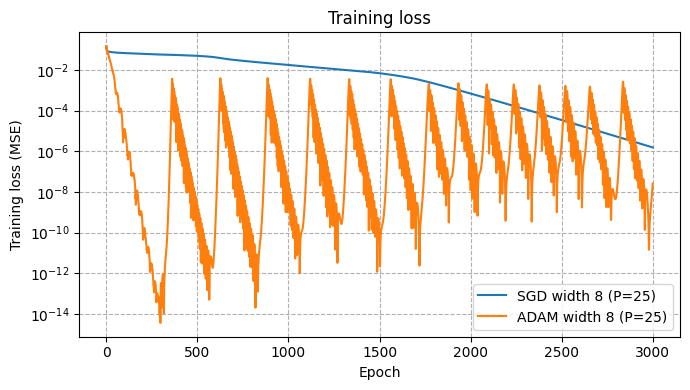

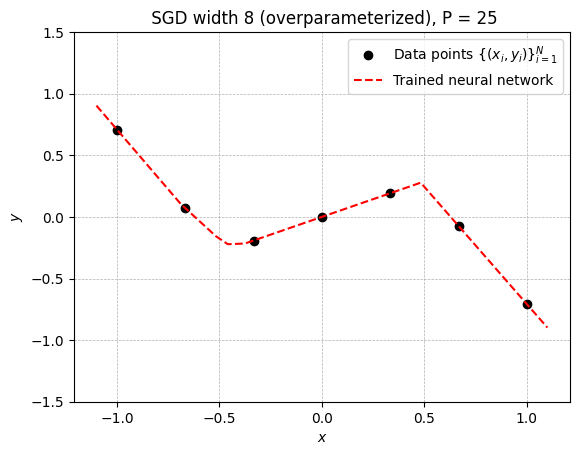

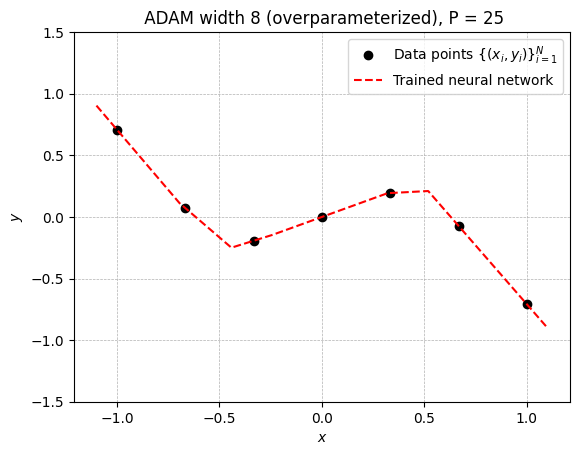

In [ ]:
modelSGD = Model(width=8, activation=nn.ReLU()) # model
modelADAM = Model(width=8, activation=nn.ReLU())

# both networks identical initial parameters- so we do not affect the initial points!!!
modelADAM.load_state_dict(modelSGD.state_dict())

optimizerSGD = optim.SGD(modelSGD.parameters(), lr=0.1)
optimizerADAM = optim.Adam(modelADAM.parameters(), lr=0.1) # different values for this one change oscillations

hist_SGD=train(modelSGD, optimizerSGD, 3000) # Train for 3000 epochs
hist_ADAM=train(modelADAM, optimizerADAM,3000)

print(f" SGD width 8: P = {count_params(modelSGD)}, final training loss = {hist_SGD[-1]}")
print(f"ADAM  8: P = {count_params(modelADAM)}, final training loss = {hist_ADAM[-1]}")

plot_loss(hist_SGD, hist_ADAM, modelSGD, modelADAM,"SGD width 8", "ADAM width 8", "Training loss")
plot_func(modelSGD, f" SGD width 8 (overparameterized), P = {count_params(modelSGD)}")
plot_func(modelADAM, f" ADAM width 8 (overparameterized), P = {count_params(modelADAM)}")


__e)__ Fifth, we study the loss landscape of a trained network along different directions in parameter space.  


Train an overparameterized network with ReLU activation functions at each layer. Denote it by $m(\cdot,\theta^{*})$ where $\theta^{*}$ are the learned parameters. Sample $\Delta$, with the same size as $\theta^{*}$, from a standard normal distribution (and keep it fixed). Plot

$$
\begin{align*}
    \frac{1}{N}\sum_{i=1}^N L\left(m\left(x_i;\theta^{*} + t \Delta\right),y_i\right)
\end{align*}
$$

as a function of $t\in[-1,1]$ (or even a larger interval).

Do the same for another network with the same widths and depth, but using 4 * sigmoid activation functions at each layer.

How does these two cases differ? Give a qualitative analysis.

_Hints:_ You can get the parameters as a dictionary of a model by using `model.state_dict()`, updating the parameters in the dictionary, and then loading the updated parameters into the model using `model.load_state_dict(...)`. If you use this approach it is helpful to know the difference between [a shallow copy and a deep copy of a dictionary](https://thispointer.com/python-how-to-copy-a-dictionary-shallow-copy-vs-deep-copy/) You might need to cut off values of the loss that are too high to get a nice plot.

_Optional:_ Plot in two direction at the same time, i.e. plot
$$
\begin{align*}
    \frac{1}{N}\sum_{i=1}^N L\left(m\left(x_i;\theta^{*} + t \Delta_{t} + s \Delta_{s}\right),y_i\right)
\end{align*}
$$

as a function of $t,s\in[-1,1]$.

__Solution:__

_Fill in your solution here!_

In the plot below, the training loss for a certain direction of $ (\theta^*+t\Delta)$. The same direction are used both for the ReLu and sigmoid function. The ReLu has a sharp minimum for t=0, and then the loss rises in both directions. This indicates that the network is sensitive to parameter changes in this direction. The sigmoid network is instead smoother, and has a flatter minimum and gradually increasing loss when t moves away from zero. As the trainloss is larger, the sigmoid function fits the data not as good as the ReLu model. We can conclude that the sigmoid function is more robust, in this direction of a change, but in general it does not need to be in this way, one need to test for other directions.

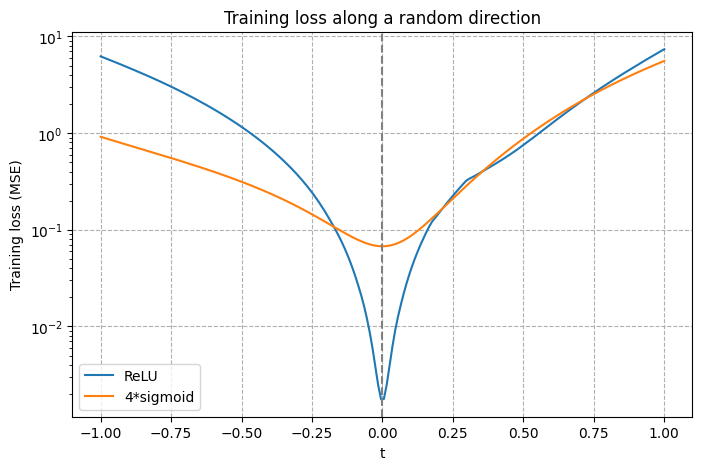

In [ ]:
import copy

# DEEP copy of the trained parameters
base_relu = copy.deepcopy(model_ReLu.state_dict())
base_sig  = copy.deepcopy(model_sig.state_dict())


torch.manual_seed(0)# want the same for every run
# This is the delta- same for both models
direction = {name: torch.randn_like(v) for name, v in base_relu.items()} # parameter name and tensor. like wegihts and biases, gives a tensor of right shape

def loss_landscape(model, base, direction, t_values):
    losses = []
    for t in t_values:
        # the dictionary for theta + t * delta
        new_params = {name: base[name] + t * direction[name] for name in base} # to add on the right parameter
        model.load_state_dict(new_params)# load the parameter again
        # Make the pred of the data set
        model.eval() # do this for PyTorch
        with torch.no_grad(): # no training
            losses.append(loss_fn(model(torch_xs), torch_ys).item()) # calcuates the MSE of the model and the correct values
    # Put theta* back into the model
    model.load_state_dict(base) # restore the org paramters
    return np.array(losses)

t_values = np.linspace(-1, 1, 200)
losses_relu = loss_landscape(model_ReLu, base_relu, direction, t_values)# for both models
losses_sig  = loss_landscape(model_sig,  base_sig,  direction, t_values)

# Plot
plt.figure(figsize=(8, 5))
plt.semilogy(t_values, np.clip(losses_relu, 1e-12, 1e2), label="ReLU") # too make the plot visabile
plt.semilogy(t_values, np.clip(losses_sig,  1e-12, 1e2), label="4*sigmoid")
plt.axvline(0, color="gray", linestyle="--")
plt.xlabel("t")
plt.ylabel("Training loss (MSE)")
plt.title("Training loss along a random direction")
plt.grid(True, linestyle="dashed")
plt.legend()
plt.show()

---
### Exercise 4: Implicit regularization via small norm in polynomial fitting in $\mathbb{R}$
_Remark:_ You should solve this exercise using `numpy` primarily.

The purpose of this exercise is to study optimization problems in the overparameterized regime, i.e., when there are multiple solutions to choose from, and see how the norm of a given solution may affect generalization.   

Again, we consider the data points $\{(x_{i},y_{i})\}_{i=1}^{N}\subseteq\mathbb{R}\times\mathbb{R}$, where $N=7$, below:

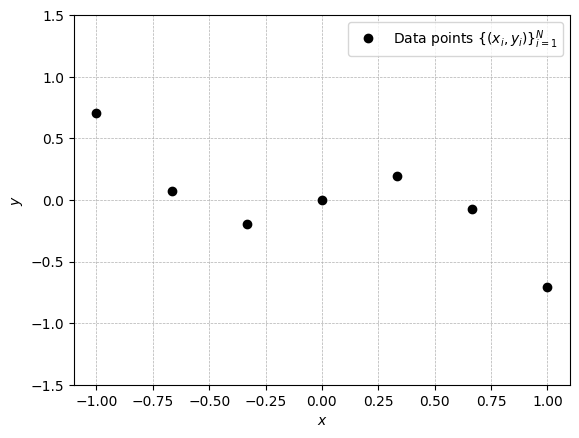

In [ ]:
N = 7 # the number of data points
xs = np.linspace(-1, 1, num=N) # the x_i's
ys = np.sin(5*xs)*np.exp(np.abs(2*xs)) / 10 # the y_i's

fig, axes = plt.subplots(dpi=100)
axes.plot(xs,ys,'ko')
axes.legend([r'Data points $\{(x_{i},y_{i})\}_{i=1}^{N}$'])
axes.set_xlabel('$x$')
axes.set_ylabel('$y$')
axes.grid(linestyle='dashed', linewidth=0.5)
axes.set_ylim([-1.5, 1.5]);

We wish to fit a polynomial model $m(\cdot;\theta)$ of degree $n=9$ (overparameterized) to the data points  $\{(x_{i},y_{i})\}_{i=1}^{N}$. One solution $m(\cdot;\theta^{*})$ is given below:

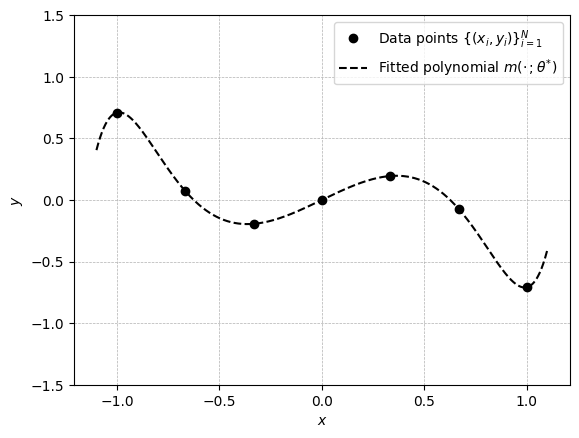

In [ ]:
theta_star = np.array([0,  0.8, 0, -1.9, 0, -0.583957507, 0, 0.28, 0, 0.695322536])
x = np.linspace(-1.1, 1.1, num = 1000)

fig, axes = plt.subplots(dpi=100)
axes.plot(xs,ys,'ko')
axes.plot(x, np.polyval(np.flip(theta_star), x),'k--')
axes.legend([r'Data points $\{(x_{i},y_{i})\}_{i=1}^{N}$', r'Fitted polynomial $m(\cdot\,;\theta^{*})$'])
axes.set_xlabel('$x$')
axes.set_ylabel('$y$')
axes.grid(linestyle='dashed', linewidth=0.5)
axes.set_ylim([-1.5, 1.5]);

---

__a)__ Recall from __Exercise 1__ __g)__ that given a candidate point $a\in\mathbb{R}^{n+1}$, we can obtain a solution via the Euclidean projection formula $\theta^{*} = a - X^{T}(XX^{T})^{-1}(Xa-Y)$. Initialize $a$ randomly and compute the projection $\theta^{*}$ and plot the fitted polynomial $m(\cdot;\theta^{*})$ as above. Vary the magnitude or norm of $\theta^{*}$ indirectly by multiplying $a$ by $0$, $10$, $100$ and $1000$. Visually, how does the generalization of $m(\cdot;\theta^{*})$ correspond to the norm of $\theta^{*}$?

__Solution:__

_Fill in your solution here!_

We see that as the norm of θ grows, the fit of the polynomial overshoots the datapoints. Visually, the lower norm generalizes better, as the polynomial passes through the datapoints smoothly.

scale     0: ||theta*||_2 = 2.269e+00, max |X theta* - Y| = 5.0e-15
scale    10: ||theta*||_2 = 2.015e+01, max |X theta* - Y| = 8.7e-14
scale   100: ||theta*||_2 = 2.002e+02, max |X theta* - Y| = 1.2e-12
scale  1000: ||theta*||_2 = 2.002e+03, max |X theta* - Y| = 8.3e-12


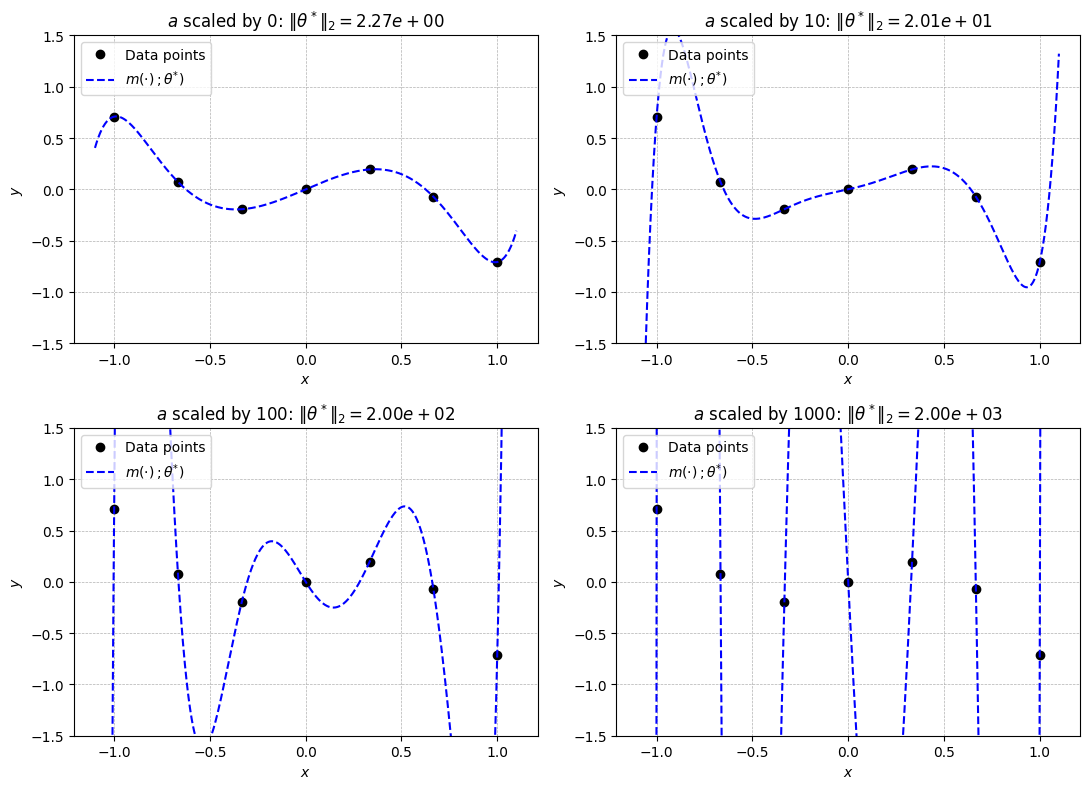

In [ ]:
from matplotlib.lines import lineStyles
n = 9 # degree
a = np.random.randn(n + 1)

# Write your code here

def feature_matrix(x,n):
  #rows of phi(x_i).T = (1, x_i, x_i^2, ... , x_i^n) so this method stacks these rows, each one increasing in power
  return np.array([x**i for i in range(n+1)]).T

def euc_proj(a, X, Y):
  #we use the answer from 1g)
  return a - X.T @ np.linalg.solve(X @ X.T, X @ a - Y) #linalg.solve(a,b) returns the answer to ax = b, so we use it here to skip the inverse computation

X = feature_matrix(xs, n) #feature matrix for datapoints
x_plot = np.linspace(-1.1, 1.1, num=1000) #create plotting points
X_plot = feature_matrix(x_plot, n) #featurematrix for plotting

scales = [0, 10 , 100, 1000]
fig, axes = plt.subplots(2,2, figsize=(11,8), dpi=100)

for ax, s in zip(axes.flat, scales):
  theta = euc_proj(s * a, X, ys)
  ax.plot(xs, ys, 'ko', label='Data points')
  ax.plot(x_plot, X_plot @ theta, 'b--', label=r'$m(\cdot)\,;\theta^{*})$')
  ax.set_title(rf'$a$ scaled by {s}: $\|\theta^*\|_2 = {np.linalg.norm(theta):.2e}$')
  ax.set_xlabel('$x$')
  ax.set_ylabel('$y$')
  ax.set_ylim([-1.5, 1.5])
  ax.grid(linestyle='dashed', linewidth=0.5)
  ax.legend(loc='upper left')
  #this checks whether theta* actually satisfies X @ theta* = Y and prints the norm of theta
  print(f"scale {s:5d}: ||theta*||_2 = {np.linalg.norm(theta):.3e}, "
          f"max |X theta* - Y| = {np.max(np.abs(X @ theta - ys)):.1e}")
plt.tight_layout()
plt.show()

__b)__ Implement the GD method for optimization problem (2) in __Exercise 1__ above, starting at $\theta_{0}=0$, using step size $\gamma_{k} = 1/\beta$, and verify that the resulting sequence $\{\theta_{k}\}_{k\geq0}$ converges to $\theta^{*}$, where $\theta^{*}$ is the Euclidean projection starting from the candidate point $a=0$. I.e., the GD method converges to the solution with the smallest norm. Do this by plotting $||\theta_{k}-\theta^{*}||_{2}^{2}$ as a function of $k$ in log-linear scale.

_Remark:_ We consider $\theta_{k}$ to have converged to $\theta^{*}$ if $||\theta_{k}-\theta^{*}||_{2}^{2} \leq 10^{-16}$.


__Solution:__

_Fill in your solution here!_

converged after 20182 iterations: ||theta_k - theta*||^2 = 9.99e-17


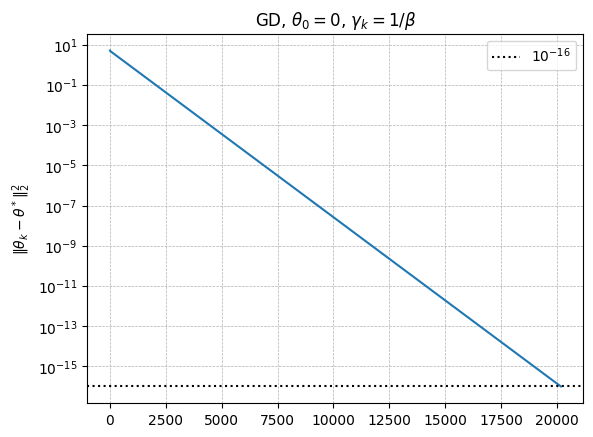

In [ ]:
# Write your code here
X = feature_matrix(xs, n) #reuse method from 4a)
N = len(ys)

theta_star = euc_proj(np.zeros(n + 1), X, ys) #Euclidian projection starting at a=0

beta = 2 / N * np.linalg.norm(X.T @ X, 2) #smoothness from 1h), we use 2norm and NOT frobenius
gamma = 1 / beta

def grad_f(theta):
  return 2 / N * X.T @ (X @ theta - ys) #gradient of f from 1b)

theta = np.zeros(n+1) #theta_0 = 0
dist = [np.sum((theta - theta_star) ** 2)] #||theta_k - theta*||^2, init distance book keeping for convergence
max_iter = 10**6
convergence_criteria = 1e-16

for k in range(max_iter):
  theta = theta - gamma * grad_f(theta)
  dist.append(np.sum((theta - theta_star) ** 2))
  if dist[-1] <= convergence_criteria:
    break

print(f"converged after {len(dist)} iterations: "
      f"||theta_k - theta*||^2 = {dist[-1]:.2e}")

#plotting
fig, ax = plt.subplots(dpi=100)
ax.semilogy(np.arange(len(dist)), dist)
ax.axhline(1e-16, color='k', linestyle=':', label=r'$10^{-16}$')
ax.set_ylabel(r'$\|\theta_k - \theta^*\|_2^2$')
ax.set_title(r'GD, $\theta_0 = 0$, $\gamma_k = 1/\beta$')
ax.grid(linestyle='dashed', linewidth=0.5)
ax.legend()
plt.show()


---

__c)__ Implement the SGD method for optimization problem (1) in __Exercise 1__ above, starting at $\theta_{0}=0$, using step size $\gamma_{k} = 0.1 / \beta$, and verify that the resulting sequence $\{\theta_{k}\}_{k\geq0}$ converges to $\theta^{*}$, where $\theta^{*}$ is the Euclidean projection starting from the candidate point $a=0$. I.e., the SGD method converges to the solution with the smallest norm. Do this by plotting $||\theta_{k}-\theta^{*}||_{2}^{2}$ as a function of $k$ in log-linear scale.


__Solution:__


_Fill in your solution here!_

converged after 2902976 iterations: ||theta_k - theta*||^2 = 1.00e-16


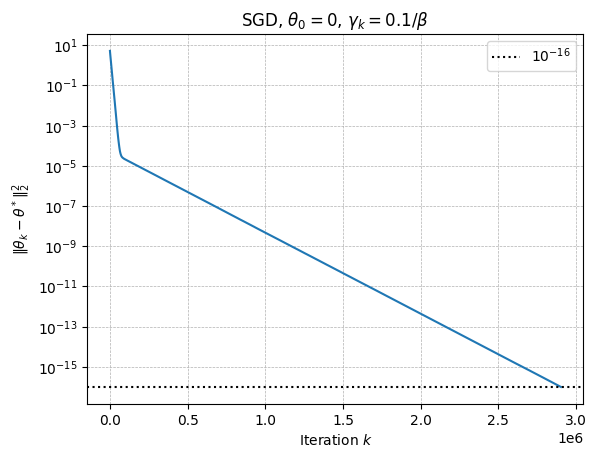

In [ ]:
# Write your code here
X = feature_matrix(xs, n)
N = len(ys)

#euclidian projection with a = 0
theta_star = euc_proj(np.zeros(n + 1), X, ys)

beta = 2 / N *np.linalg.norm(X.T @ X, 2) #from 1h) 2-norm NOT frobenius
gamma = 0.1 / beta

def grad_f_i(theta, i):
  #gradient of f_i(theta) from 1b)
  return 2 * (X[i] @ theta - ys[i]) * X[i]

np.random.seed(42) #for repoducible plots
theta = np.zeros(n + 1) #thet_0 = 0
dist = [np.sum((theta - theta_star) ** 2)] #init distance book keeping
max_iter = 10**7
convergence_criteria = 1e-16

for k in range(max_iter):
  i = np.random.randint(N) #pick i uniformly at random
  theta = theta - gamma * grad_f_i(theta, i)
  dist.append(np.sum((theta - theta_star) ** 2))
  if dist[-1] <= convergence_criteria:
    break

#printing
print(f"converged after {len(dist)} iterations: "
      f"||theta_k - theta*||^2 = {dist[-1]:.2e}")

#plotting
fig, ax = plt.subplots(dpi=100)
ax.semilogy(np.arange(len(dist)), dist)
ax.axhline(1e-16, color='k', linestyle=':', label=r'$10^{-16}$')
ax.set_xlabel('Iteration $k$')
ax.set_ylabel(r'$\|\theta_k - \theta^*\|_2^2$')
ax.set_title(r'SGD, $\theta_0 = 0$, $\gamma_k = 0.1/\beta$')
ax.grid(linestyle='dashed', linewidth=0.5)
ax.legend()
plt.show()


---

__d)__ The ADAM optimization method is given by:

- Pick $\theta_{0}\in\mathbb{R}^{n+1}$, $\hat{m}_{0}=\hat{v}_{0}=0\in\mathbb{R}^{n+1}$, $b_{m},b_{v}\in(0,1)$ and $\gamma,\epsilon>0$.
- For $k\geq 0$:
    - Pick $i\in\{1,\ldots, N\}$ uniformly at random
    - Set $g_{k+1} = \nabla f_{i}(\theta_{k})$
    - Set $\hat{m}_{k+1} = b_{m}\hat{m}_{k}+(1-b_{m})g_{k+1}$
    - Set $\hat{v}_{k+1} = b_{v}\hat{v}_{k}+(1-b_{v})g_{k+1}^{2}$ (element-wise square)
    - Set $m_{k+1}=\hat{m}_{k+1}/(1-b_{m}^{k+1})$
    - Set $v_{k+1}=\hat{v}_{k+1}/(1-b_{v}^{k+1})$
    - Set $\theta_{k+1} = \theta_{k} - \gamma m_{k+1} ./ (\sqrt{v_{k+1}} + \epsilon\mathbb{1})$ (element-wise division and square root)

Use the [suggested values](https://arxiv.org/pdf/1412.6980.pdf):

- $b_{m} = 0.9$
- $b_{v} = 0.999$
- $\gamma = 0.001$
- $\epsilon = 10^{-8}$

Implement the ADAM optimization method for optimization problem (1) in __Exercise 1__ above, starting at $\theta_{0}=0$. Does ADAM converge to the minimum norm solution? Plot the resulting model.

__Solution:__


_Fill in your solution here!_

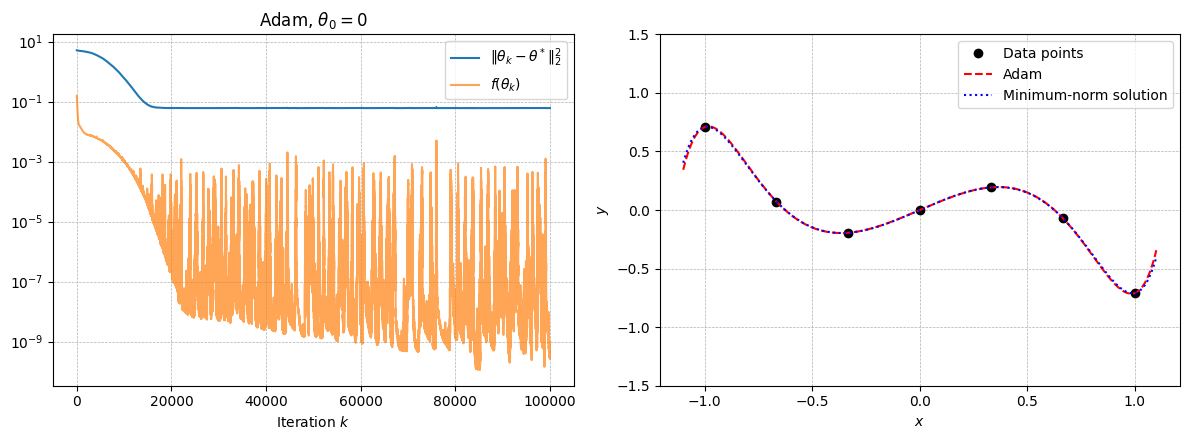

In [ ]:
# Write your code here

#same old same old
X = feature_matrix(xs, n)
N = len(ys)
theta_star = euc_proj(np.zeros(n + 1), X, ys)

def f(theta):
  #least squares objective
  return np.mean((X @ theta - ys) ** 2)


b_m = 0.9
b_v = 0.999
gamma = 0.001
eps = 1e-8

np.random.seed(67)
#just a bunch of zeros
theta = np.zeros(n + 1)
m_hat = np.zeros(n + 1)
v_hat = np.zeros(n + 1)
dist = [np.sum((theta - theta_star)**2)]
loss = [f(theta)]
max_iter = 10**5

for k in range(max_iter):
  i = np.random.randint(N) #uniform at random
  g = grad_f_i(theta, i)
  m_hat = b_m * m_hat + (1 - b_m) * g
  v_hat = b_v * v_hat + (1 - b_v) * g**2       # element-wise square
  m = m_hat / (1 - b_m**(k + 1))               # bias correction
  v = v_hat / (1 - b_v**(k + 1))
  theta = theta - gamma * m / (np.sqrt(v) + eps)   # element-wise
  dist.append(np.sum((theta - theta_star)**2))
  loss.append(f(theta))


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), dpi=100)
axes[0].semilogy(dist, label=r'$\|\theta_k - \theta^*\|_2^2$')
axes[0].semilogy(loss, label=r'$f(\theta_k)$', alpha=0.7)
axes[0].set_xlabel('Iteration $k$')
axes[0].set_title(r'Adam, $\theta_0 = 0$')
axes[0].grid(linestyle='dashed', linewidth=0.5)
axes[0].legend()

x_plot = np.linspace(-1.1, 1.1, num=1000)
X_plot = feature_matrix(x_plot, n)
axes[1].plot(xs, ys, 'ko', label='Data points')
axes[1].plot(x_plot, X_plot @ theta, 'r--', label='Adam')
axes[1].plot(x_plot, X_plot @ theta_star, 'b:', label='Minimum-norm solution')
axes[1].set_xlabel('$x$'); axes[1].set_ylabel('$y$')
axes[1].set_ylim([-1.5, 1.5])
axes[1].grid(linestyle='dashed', linewidth=0.5)
axes[1].legend()
plt.tight_layout()
plt.show()

ADAM does not converge. The objective $f(\theta_k)$ goes close to zero, so Adam finds a solution, but $\lVert\theta_k - \theta^*\rVert_2^2$ levels off and stops decreasing. Adam therefore converges to a different solution than the minimum-norm one, even though the two fitted polynomials look almost the same in the right figure.

---

__e)__ The ADAM optimization method scales the gradient independently in each coordinate. We call such methods diagonally scaled methods.

Now, recall the scaled projection problem from __Exercise 1__ __g)__ above: given a candidate point $a\in\mathbb{R}^{n+1}$, we can obtain a solution via the scaled projection formula $\theta^{*} = a - H^{-1}X^{T}(X H^{-1} X^{T})^{-1}(Xa-Y)$.


Consider the candidate point $a\in\mathbb{R}^{n+1}$ and the highly skewed diagonal scaling matrix $H\in\mathbb{S}^{n+1}_{++}$ below:

In [ ]:
a = np.zeros(n + 1)
H_inv = np.diag(np.logspace(-10, 10, num = n + 1)) # the inverse of H



Plot the data points $\{(x_{i},y_{i})\}_{i=1}^{N}$ and the fitted polynomial $m(\cdot;\theta^{*})$ in the same figure using the scaled projection formula. Visually, does the fitted polynomial $m(\cdot;\theta^{*})$ seem to generalize well?

__Solution:__

_Fill in your solution here!_

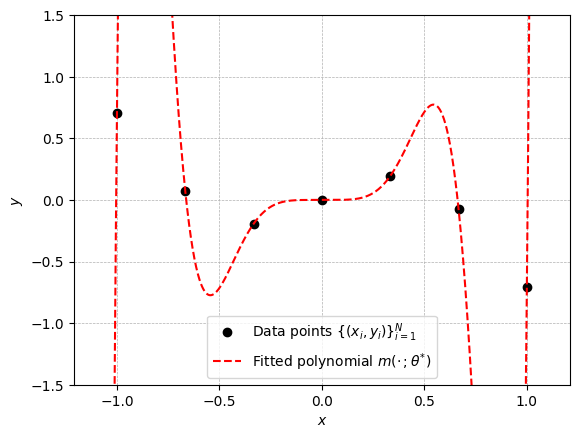

In [ ]:
# Write your code here
def scaled_proj(a, X, Y, H_inv):
  return a - H_inv @ X.T @ np.linalg.solve(X @ H_inv @ X.T, X @ a - Y) #same linalg solve trick as before to skip inverse martix

X = feature_matrix(xs, n)
theta_scaled = scaled_proj(a, X, ys, H_inv)

#plotting
x_plot = np.linspace(-1.1, 1.1, num=1000)
X_plot = feature_matrix(x_plot, n)

fig, ax = plt.subplots(dpi=100)
ax.plot(xs, ys, 'ko', label=r'Data points $\{(x_{i},y_{i})\}_{i=1}^{N}$')
ax.plot(x_plot, X_plot @ theta_scaled, 'r--', label=r'Fitted polynomial $m(\cdot\,;\theta^{*})$')
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')
ax.set_ylim([-1.5, 1.5])
ax.grid(linestyle='dashed', linewidth=0.5)
ax.legend()
plt.show()

Looking at the fitted polynomial, it does not generalize well. The polynomial passes through all datapoints (which is to be expected since the problem is overparameterized). However, the polynomial oscillations between the datapoints, which makes the fit of the model seem unnatural to the human eye.

---

__f)__ The scaled GD method is given by
- Pick $\theta_{0}\in\mathbb{R}^{n+1}$ and $H\in\mathbb{S}_{+}^{n+1}$
- For $k\geq 0$:
    - Set $\theta_{k+1} = \theta_{k} - \gamma_{k} H^{-1}\nabla f(\theta_{k})$ for some $\gamma_{k}>0$.

For numerical reasons (i.e., so that the algorithm converges in reasonable time), consider the less skewed diagonal scaling matrix below:

In [ ]:
H_inv = np.diag(np.logspace(-3, 0, num = n + 1)) # the inverse of H

Starting at $\theta_{0}=0$ and using the step size $\gamma_{k}=1/\beta_{H}$, show that the scaled GD method converges to the scaled projection point $\theta^{*}=a - H^{-1}X^{T}(X H^{-1} X^{T})^{-1}(Xa-Y)$ for $a=0$.

Here, $\beta_{H}$ is given by

\begin{align}
    \beta_{H} = \frac{2}{N}\left\lVert H^{-\frac{1}{2}}X^{T}X H^{-\frac{1}{2}} \right\rVert_{2},
\end{align}

where $H^{-\frac{1}{2}}$ is the symmetric square root of $H^{-1}$.

__Solution:__

_Fill in your solution here!_

Converged after 264895 iterations: ||theta_k - theta*||^2 = 1.00e-16


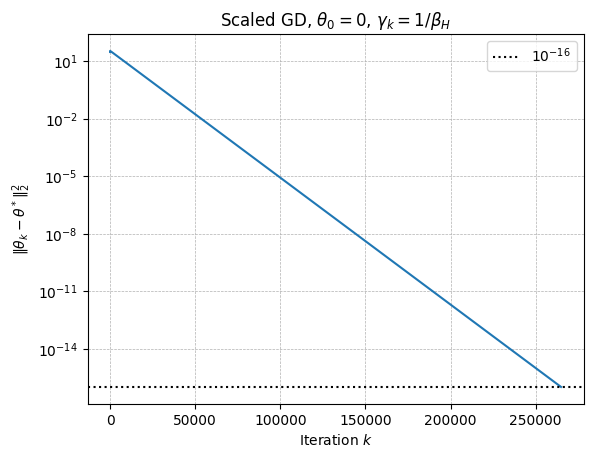

In [ ]:
# Write your code here
X = feature_matrix(xs, n)
N = len(ys)

#same projetion as before
theta_star = scaled_proj(np.zeros(n + 1), X, ys, H_inv)

H_inv_sqrt = np.diag(np.sqrt(np.diag(H_inv))) #symmetric square root = element wise sqrt of diagonal
beta_H = 2 / N * np.linalg.norm(H_inv_sqrt @ X.T @ X @ H_inv_sqrt, 2) #we use the 2 norm again
gamma = 1 / beta_H

def grad_f(theta):
  #grad from 1b)
  return 2 / N * X.T @ (X @ theta - ys)

theta = np.zeros(n + 1) #theta_0 = 0
dist = [np.sum((theta - theta_star)**2)] #2norm of dist between theta_k and theta* squared
max_iter = 10**7
convergence_criteria = 1e-16

for k in range(max_iter):
  theta = theta - gamma * H_inv @ grad_f(theta) #take the step as per instruction
  dist.append(np.sum((theta - theta_star) ** 2)) #book keeping
  if dist[-1] <= convergence_criteria:
    break

#nice print
print(f"Converged after {len(dist)-1} iterations: "
      f"||theta_k - theta*||^2 = {dist[-1]:.2e}")

#nice plot
fig, ax = plt.subplots(dpi=100)
ax.semilogy(np.arange(len(dist)), dist)
ax.axhline(1e-16, color='k', linestyle=':', label=r'$10^{-16}$')
ax.set_xlabel('Iteration $k$')
ax.set_ylabel(r'$\|\theta_k - \theta^*\|_2^2$')
ax.set_title(r'Scaled GD, $\theta_0 = 0$, $\gamma_k = 1/\beta_H$')
ax.grid(linestyle='dashed', linewidth=0.5)
ax.legend()
plt.show()

---
### Exercise 5: Implicit regularization via flatness
_Remark:_ You should solve this exercise using `numpy` primarily.

It has been observed in the [literature](https://arxiv.org/pdf/1609.04836.pdf) that flat mimima tend to lead to better generalization than sharp minima. In this exercise, we empirically verfiy that SGD tends to favour flat mimima.

Consider the finite-sum problem problem
$$
\begin{equation}
\begin{aligned}
& \underset{x\in\mathbb{R}}{\mathrm{minimize}}
& & f(x)= \frac{1}{N} \sum_{i=1}^{N}f_{i}(x)
\end{aligned}
\end{equation}
$$
where the $f_{i}$'s and $f$ are given below: (the derivatives are also given for convenience.)

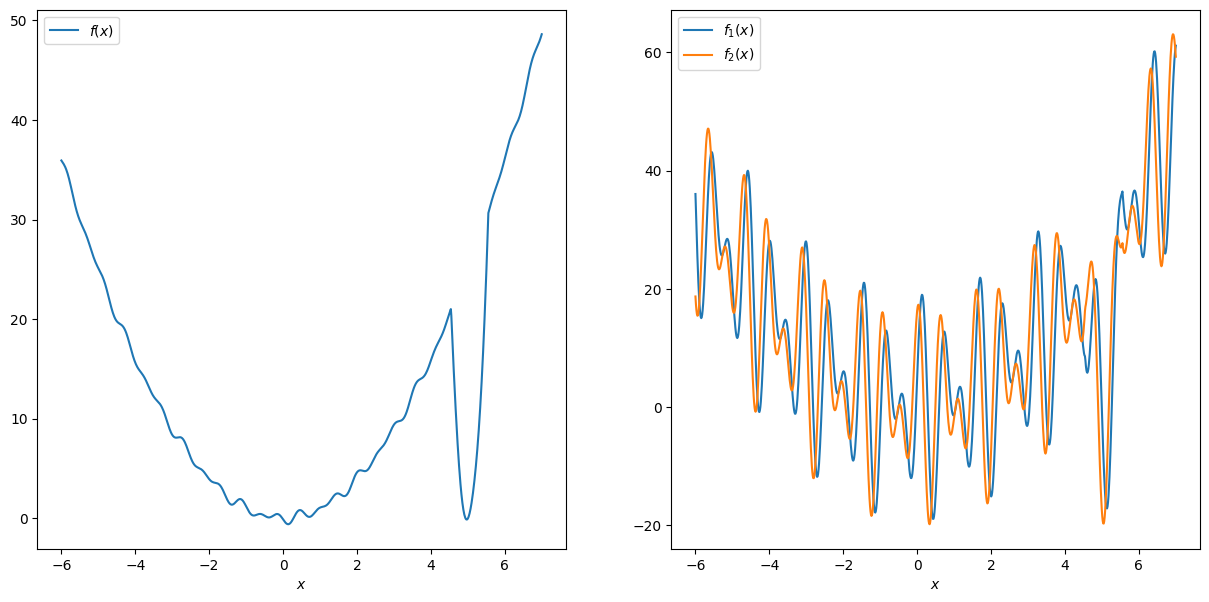

In [ ]:
from functools import partial

def loss_term(phase, x):
    if x < 50/11:
        value = x**2
    elif x < 50/9:
        value = 100*(x - 5)**2
    else:
        value = x**2
    return value + 20*np.sin(10*x + phase)*np.cos(2*(x - 5))

def derivative_of_loss_term(phase, x):
    if x < 50/11:
        value = 2*x
    elif x < 50/9:
        value = 200*(x - 5)
    else:
        value = 2*x
    return value + 20*(10*np.cos(10*x + phase)*np.cos(2*(x - 5)) - 2*np.sin(10*x + phase)*np.sin(2*(x - 5)))

N = 2000 # the number of summands
np.random.seed(0)
phases = 2 * np.pi * np.random.rand(N)

# The induvidual summands f_i as a list
f_i_s = list(map(lambda phase : np.vectorize(partial(loss_term, phase)), phases))

# The function f
f = np.vectorize(lambda x : np.mean([f_i(x) for f_i in f_i_s]))

# Derivatives are provided for convenience
derivative_f_i_s = list(map(lambda phase : np.vectorize(partial(derivative_of_loss_term, phase)), phases))
derivative_f = np.vectorize(lambda x : np.mean([d_f_i(x) for d_f_i in derivative_f_i_s]))

x = np.linspace(-6, 7, num=1000)
y_1 = f_i_s[0](x)
y_2 = f_i_s[1](x)
y = f(x)

fig, axes = plt.subplots(1, 2, figsize=(15,7))
axes[0].plot(x, y)
axes[0].legend(["$f(x)$"])
axes[0].set_xlabel('$x$')
axes[1].plot(x, y_1)
axes[1].plot(x, y_2)
axes[1].legend(["$f_{1}(x)$", "$f_{2}(x)$"])
axes[1].set_xlabel('$x$');

Note that the function $f$ has a flat minimum close to $0$ and a sharp minimum close to $5$. Implement both GD and SGD for this problem:

- Start at $x_{0}=5$, i.e., close to the sharp minimum.
- Let both GD and SGD go for $2000$ iterations.
- Use the same constant step size $\gamma_{k} = 0.001$ for SGD and GD.
- You should notice that SDG manages to escape the sharp minimum and find the flat minimum (most of the time), while GD does not. Illustrate this by plotting $x_{k}$ as a function of $k$ for both methods.  (Common mistake: We are not asking for $f(x_k)$ vs $x_k$.)

Give some brief comments.

__Solution:__

_Fill in your solution here!_

In the plots below, with one run of GD and ten for SGD, we see that that SGD escaped the sharp minima and converges towards the flatter minima eight times. This is expected, since the gradient of SGD is generated with a small noise. At each iteration time there's a chance that the noise is enough to bring the algorithm outside of the sharp minima and start to converge towards the flatter minima around zero. Since this minima is "broader", once the SGD is there, its harder for it to escape, since the small noise is not enough to make it escape. For some low-level validation, we also tried running it for 10,000 iterations, and for that number all ten of SGD runs ended at x=0 each time.

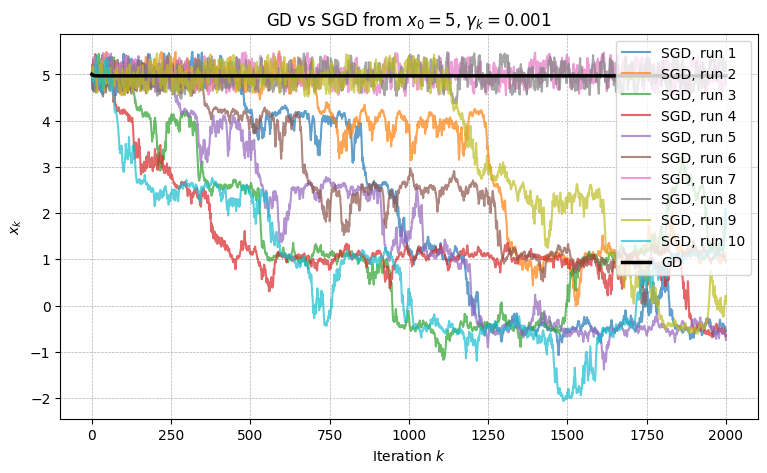

In [ ]:
# Write your code here
x0 = 5
gamma = 0.001
num_iter = 2000

def grad_f(x):
  return np.mean(derivative_of_loss_term(phases, x))

#grad descent
x_gd = np.zeros(num_iter + 1)
x_gd[0] = x0
for k in range(num_iter):
    x_gd[k + 1] = x_gd[k] - gamma * grad_f(x_gd[k]) #take GD step

#SGD
np.random.seed(42)
num_runs = 10
x_sgd = np.zeros((num_runs, num_iter + 1)) #x values for the runs
x_sgd[:, 0] = x0 #set all starting values of the rows to x0

for r in range(num_runs):
  for k in range(num_iter):
    i = np.random.randint(N) #pick random
    x_sgd[r, k + 1] = x_sgd[r, k] - gamma * derivative_f_i_s[i](x_sgd[r, k]) #one step, call derivative function for the x_k step on row r

#plotting
fig, ax = plt.subplots(figsize=(9, 5), dpi=100)
for r in range(num_runs):
    ax.plot(x_sgd[r], alpha=0.7, label=f'SGD, run {r+1}')
ax.plot(x_gd, 'k', linewidth=2.5, label='GD')
ax.set_xlabel('Iteration $k$')
ax.set_ylabel('$x_k$')
ax.set_title(r'GD vs SGD from $x_0 = 5$, $\gamma_k = 0.001$')
ax.grid(linestyle='dashed', linewidth=0.5)
ax.legend(loc='upper right')
plt.show()
